# 7 — Projections & sense lineages

Downstream of `6_embedding-classification-applied.ipynb`, which writes
`data/large_files/<term>_embeddigings_full_classified.parquet`: the **full** concordances
labelled by the embedding classifier (`class_<model>_embedding_pred`).

Two **variants** are kept side by side:

- **sample** — `*_sample2000_classified_embeddings.parquet` (2 000 rows; good for scatter/2-D)
- **full** — the applied notebook's output (~100 k passio / ~16 k pathos rows)

Sections: data → embeddings → diagnostic → context maps → LDA view → century composition →
lineage (**both variants**) → curated ERC figure (**sample only**) → shared projection
(**both variants**). Everything is dimension-agnostic: edit `EMB_SPEC`.

## 1. Setup

In [1]:
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reload helpers after editing them (from x import y binds names, not modules).
import projections_helpers, lda_projections
importlib.reload(projections_helpers)
importlib.reload(lda_projections)
from projections_helpers import build_embedding_matrix

DATA = Path("../data")
FULL_DIR = DATA / "large_files"
FIGDIR = Path("../figures"); FIGDIR.mkdir(exist_ok=True)

TERMS = ["passio", "pathos"]
SEED = 42
MIN_CENTURY_SAMPLES = 3     # minimum rows for a valid (sense, century) centroid
SAMPLE_CAP = 5000           # subsample cap for expensive 2-D methods
ELEV, AZIM = 20, -60        # 3-D view angles
FIG_CAP = 4000              # scatter cap for the ERC figure

# Curated, colourblind-safe qualitative palette (Okabe–Ito + 2). One colour per
# (lexeme, sense) so EVERY figure uses the same colour for the same sense.
CURATED_10 = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7",
              "#56B4E9", "#F0E442", "#333333", "#999999", "#8C564B"]
print("terms:", TERMS)

2026-10-14 07:07:00.457584: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-14 07:07:00.491485: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


terms: ['passio', 'pathos']


## 2. Data (both variants)

Load the 2 000-row **sample** and the **full** applied output, if present. Dates
(`random_date`) and century midpoints are derived here — they are not raw columns.

In [2]:
import tempun

model = "qwen3.8:27b"

def century_midpoint(year):
    """Year -> century midpoint (BCE-safe); year 0 -> None."""
    if pd.isna(year):
        return None
    year = int(year)
    if year == 0:
        return None
    if year < 0:
        c = (-year + 99) // 100
        return -(c * 100 - 50)
    c = (year - 1) // 100 + 1
    return (c - 1) * 100 + 50


def _random_date(row):
    d = tempun.model_date(row["not_before"], row["not_after"])
    if isinstance(d, (list, tuple, np.ndarray)):
        d = d[0]
    return d


def prepare(df):
    """Pick the label column, derive dates/century/sense, drop unusable rows."""
    pred = [c for c in df.columns if c.endswith("_embedding_pred")]
    label_col = pred[0] if pred else sorted(c for c in df.columns if c.startswith("class_"))[0]
    df = df[df[label_col]!=0]
    df = df[df[label_col].notna()].copy()
    if "random_date" not in df.columns:
        df["random_date"] = df.apply(_random_date, axis=1)
    df = df[df["random_date"].notna()].copy()
    df["sense"] = df[label_col].astype(int)
    df["century"] = df["random_date"].map(century_midpoint)
    return df, label_col


PATHS = {
    "sample": lambda t: FULL_DIR / f"{t}_sample2000_classified_embeddings.parquet",
    "full":   lambda t: FULL_DIR / f"{t}_embeddigings_full_classified.parquet",
}

VARIANTS = {}
for vname, path_for in PATHS.items():
    per_term = {}
    for term in TERMS:
        p = path_for(term)
        if not p.is_file():
            print(f"{vname:7s} {term:8s} MISSING ({p.name}) — variant skipped")
            per_term = None
            break
        df, label_col = prepare(pd.read_parquet(p))
        per_term[term] = {"df": df, "label_col": label_col}
        print(f"{vname:7s} {term:8s} rows={len(df):>7,} senses={df['sense'].nunique()}")
    if per_term is not None:
        VARIANTS[vname] = per_term

print("\nvariants available:", list(VARIANTS))

sample  passio   rows=  1,765 senses=6
sample  pathos   rows=  1,832 senses=4
full    passio   rows= 92,753 senses=6
full    pathos   rows= 16,253 senses=4

variants available: ['sample', 'full']


## 3. Embeddings & colour palette

Use the exact spec the saved classifier was trained on (`embedding_cols` + `merge_method`).
Colours are assigned **per (lexeme, sense)** from the curated palette and reused everywhere.

In [3]:
import joblib


def classifier_spec(term):
    art = DATA / f"{term}_wsd_philberta_l11_mdeberta_l9_concat.joblib"
    if art.is_file():
        a = joblib.load(art)
        return a["embedding_cols"], a["merge_method"], a.get("label_map")
    return ["emb_mdeberta_l9"], "concat", None


specs = {t: classifier_spec(t) for t in TERMS}
EMB_SPEC, EMB_METHOD, _ = specs["passio"]      # edit here to override
print(f"EMB_SPEC={EMB_SPEC}  method={EMB_METHOD}")

for vname, v in VARIANTS.items():
    for term in TERMS:
        X = build_embedding_matrix(v[term]["df"], EMB_SPEC, method=EMB_METHOD)
        v[term]["X"] = X
        v[term]["y"] = v[term]["df"]["sense"].values
        print(f"{vname:7s} {term:8s} X={X.shape}")


def sense_names(term):
    _, _, lm = specs[term]
    if lm:
        return {int(k): v.replace("_", " ") for k, v in lm.items()}
    senses = sorted(set().union(*[set(v[term]["df"]["sense"].unique())
                                  for v in VARIANTS.values()]))
    return {int(s): f"sense {s}" for s in senses}


SENSE_NAMES = {t: sense_names(t) for t in TERMS}
SENSE_KEYS = [(t, s) for t in TERMS for s in sorted(SENSE_NAMES[t])]
COLOR = {k: CURATED_10[i % len(CURATED_10)] for i, k in enumerate(SENSE_KEYS)}
SENSE_PALETTE = {t: {s: COLOR[(t, s)] for s in SENSE_NAMES[t]} for t in TERMS}
print("colours per lexeme:", {t: len(p) for t, p in SENSE_PALETTE.items()})

EMB_SPEC=['emb_philberta_l11', 'emb_mdeberta_l9']  method=concat
sample  passio   X=(1765, 1536)
sample  pathos   X=(1832, 1536)
full    passio   X=(92753, 1536)
full    pathos   X=(16253, 1536)
colours per lexeme: {'passio': 6, 'pathos': 4}


## 4. Diagnostic — how much sense structure is there? (sample)

`silhouette` rewards compact clusters; `kNN purity` detects *local* structure even when
clusters overlap. Compare against **chance**. If unsupervised methods sit near chance,
a supervised projection (LDA) is doing the real work — treat it accordingly.

In [5]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
import umap

SAMPLE = VARIANTS["sample"]


def subsample(X, y, cap=SAMPLE_CAP, seed=SEED):
    if len(X) <= cap:
        return X, y, np.arange(len(X))
    idx = np.random.default_rng(seed).choice(len(X), cap, replace=False)
    return X[idx], y[idx], idx


def knn_purity(Z, y, k=10):
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(Z))).fit(Z)
    nbr = nn.kneighbors(return_distance=False)[:, 1:]
    return float(np.mean([np.mean(y[nbr[i]] == y[i]) for i in range(len(y))]))


def chance_purity(y):
    p = np.bincount(y) / len(y)
    return float((p ** 2).sum())


def diagnose(term):
    Xs, ys, _ = subsample(SAMPLE[term]["X"], SAMPLE[term]["y"])
    views = {
        "PCA(2)":      PCA(n_components=2, random_state=SEED).fit_transform(Xs),
        "PCA10+t-SNE": TSNE(2, perplexity=30, init="pca", random_state=SEED)
                         .fit_transform(PCA(n_components=10, random_state=SEED).fit_transform(Xs)),
        "UMAP":        umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                                 random_state=SEED).fit_transform(Xs),
        "LDA(2) supervised": LDA(n_components=2, solver="svd").fit_transform(Xs, ys),
    }
    rows = [{"lexeme": term, "method": name,
             "silhouette": silhouette_score(Z, ys), "knn_purity": knn_purity(Z, ys)}
            for name, Z in views.items()]
    rows[0]["chance_knn"] = chance_purity(ys)
    return pd.DataFrame(rows)


diagnostics = pd.concat([diagnose(t) for t in TERMS], ignore_index=True)
diagnostics

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,lexeme,method,silhouette,knn_purity,chance_knn
0,passio,PCA(2),-0.028851,0.477337,0.264927
1,passio,PCA10+t-SNE,-0.036672,0.590595,NaN
2,passio,UMAP,-0.020084,0.611615,NaN
3,passio,LDA(2) supervised,0.438842,0.903286,NaN
4,pathos,PCA(2),-0.056549,0.300600,0.260462
5,pathos,PCA10+t-SNE,-0.050842,0.331659,NaN
6,pathos,UMAP,-0.066998,0.354585,NaN
7,pathos,LDA(2) supervised,0.643584,0.983679,NaN


## 5. Context maps — unsupervised 2D (sample)

Coloured by predicted sense; the honest, label-free view.

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


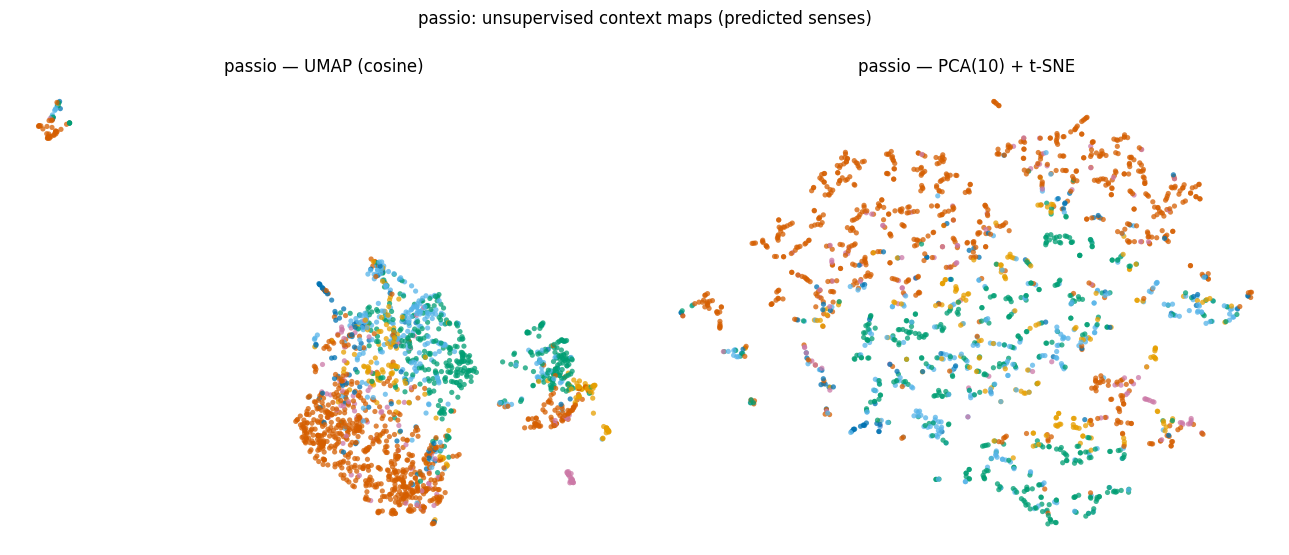

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


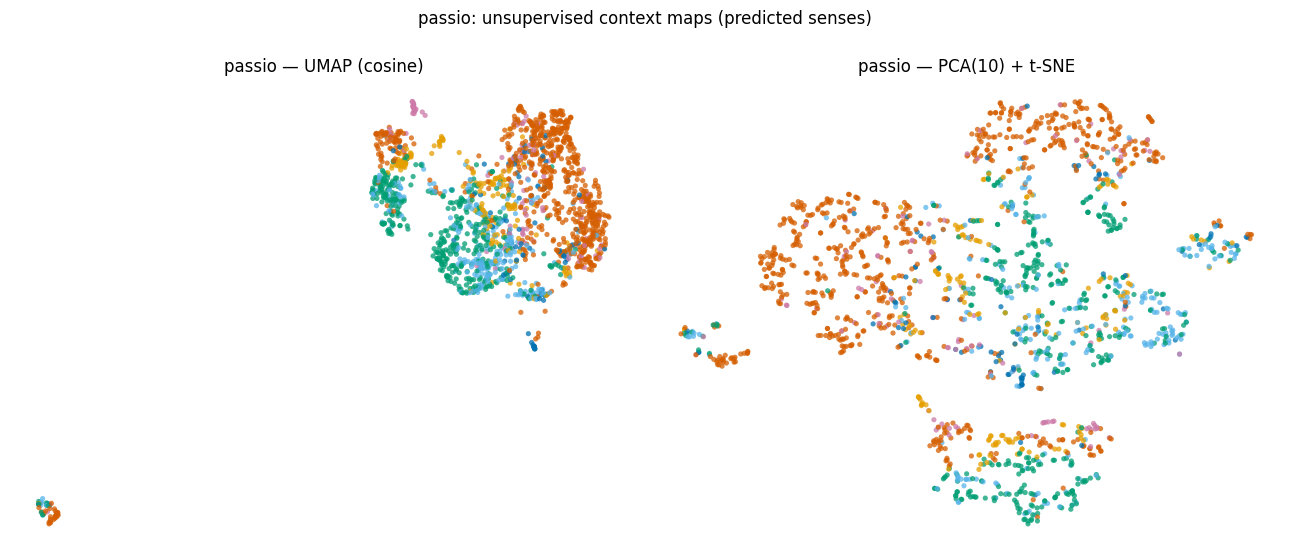

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


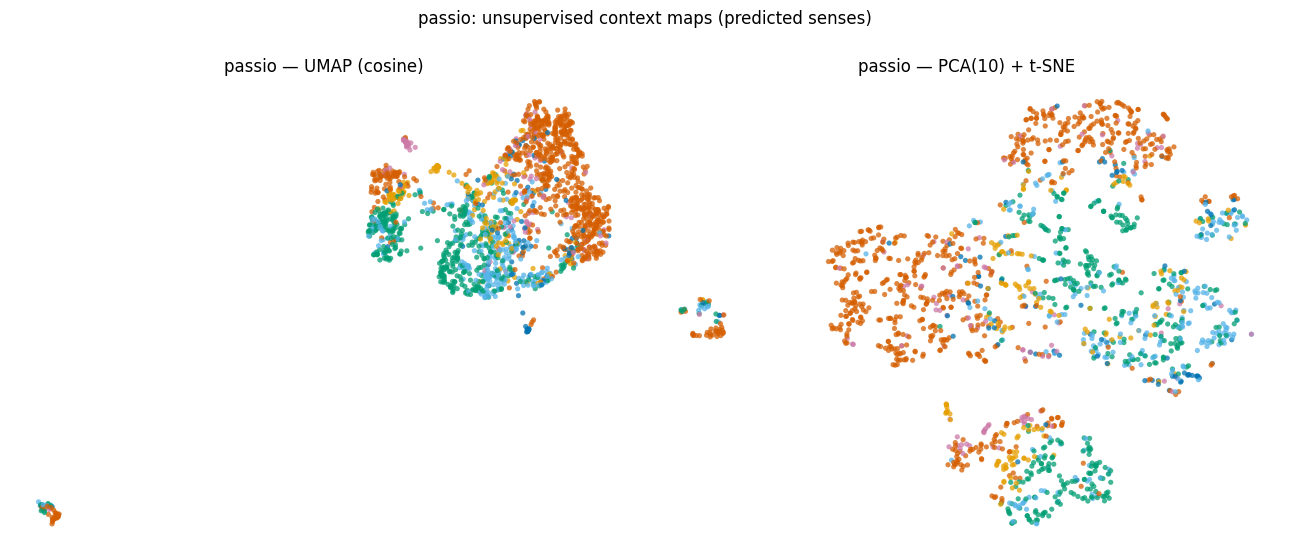

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


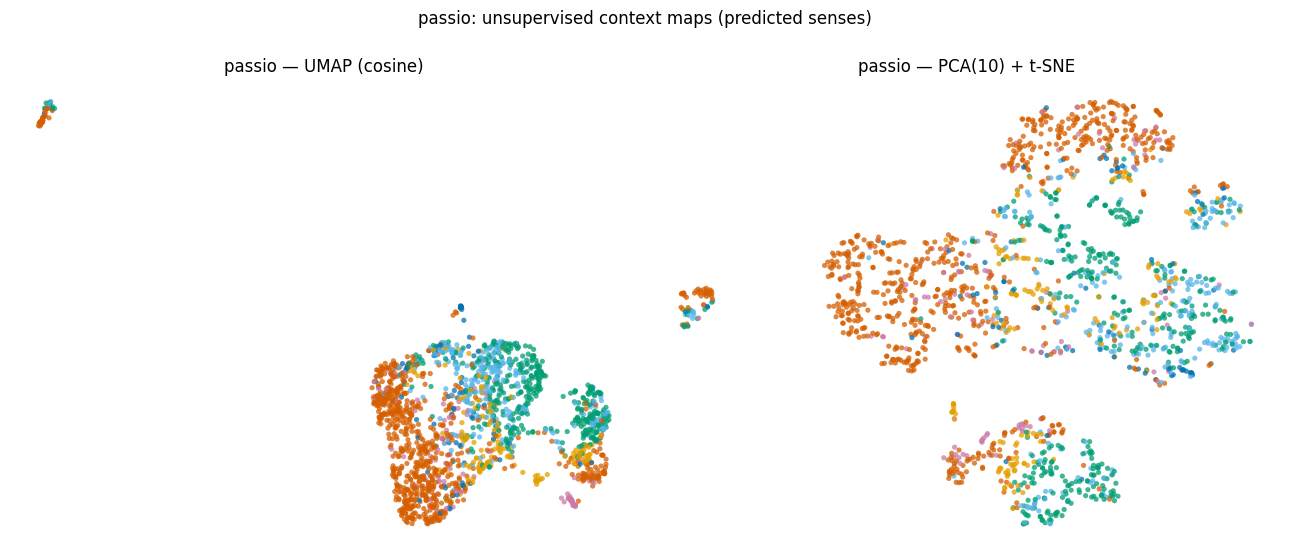

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


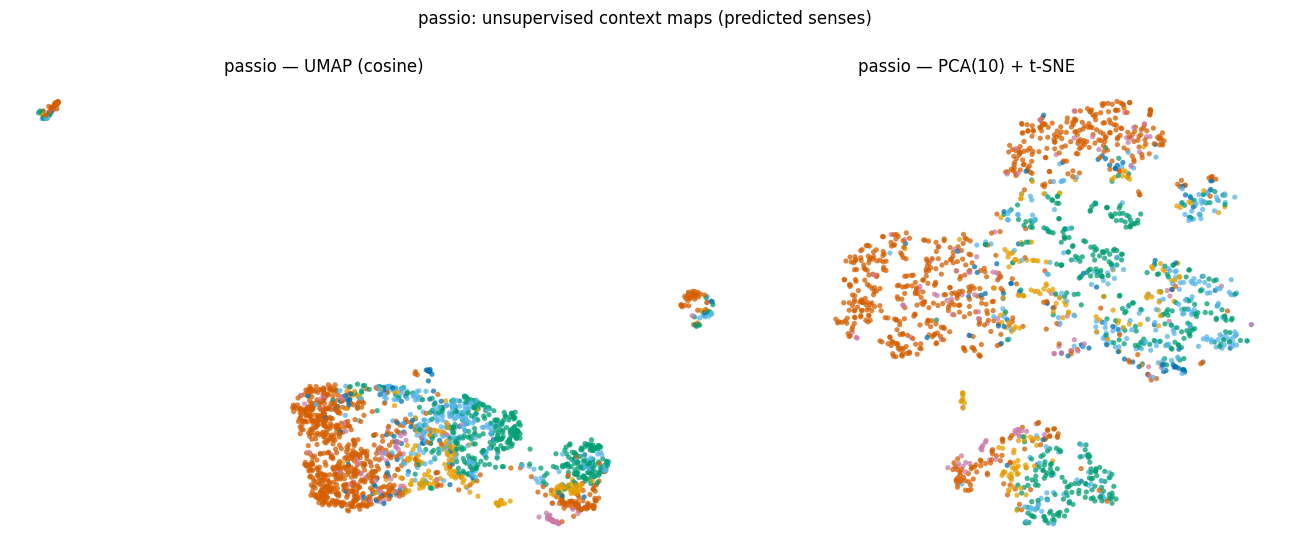

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


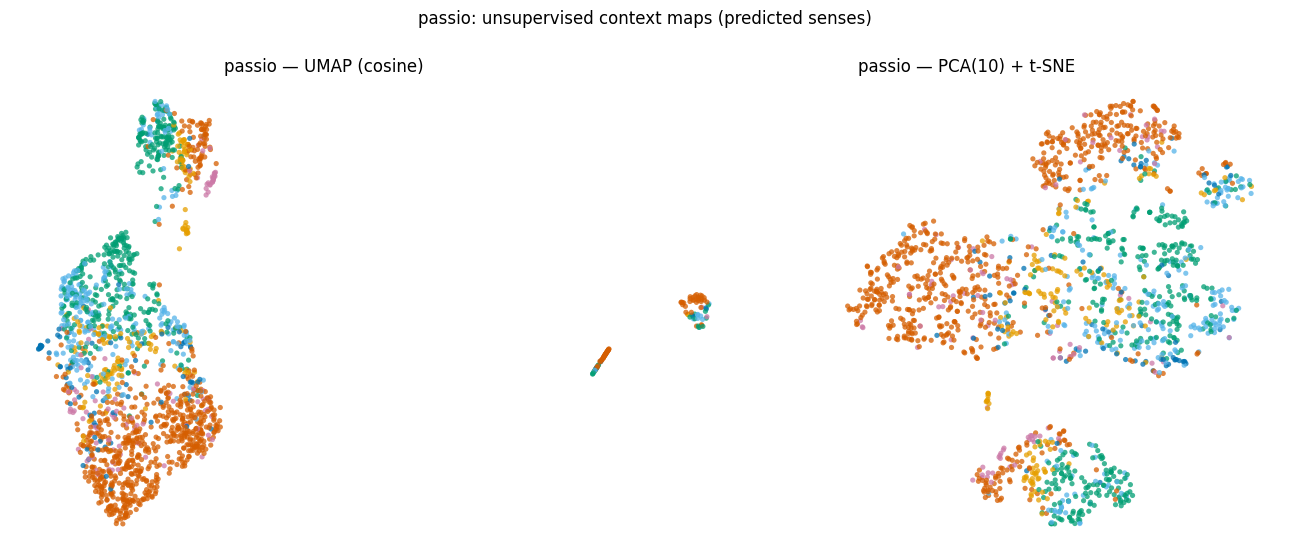

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


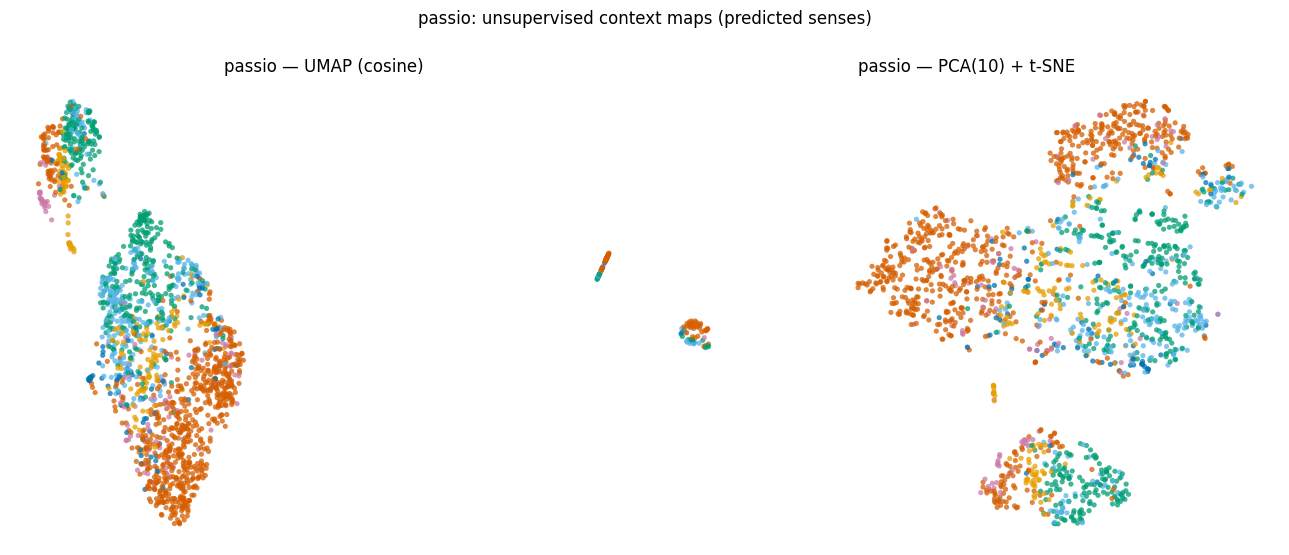

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


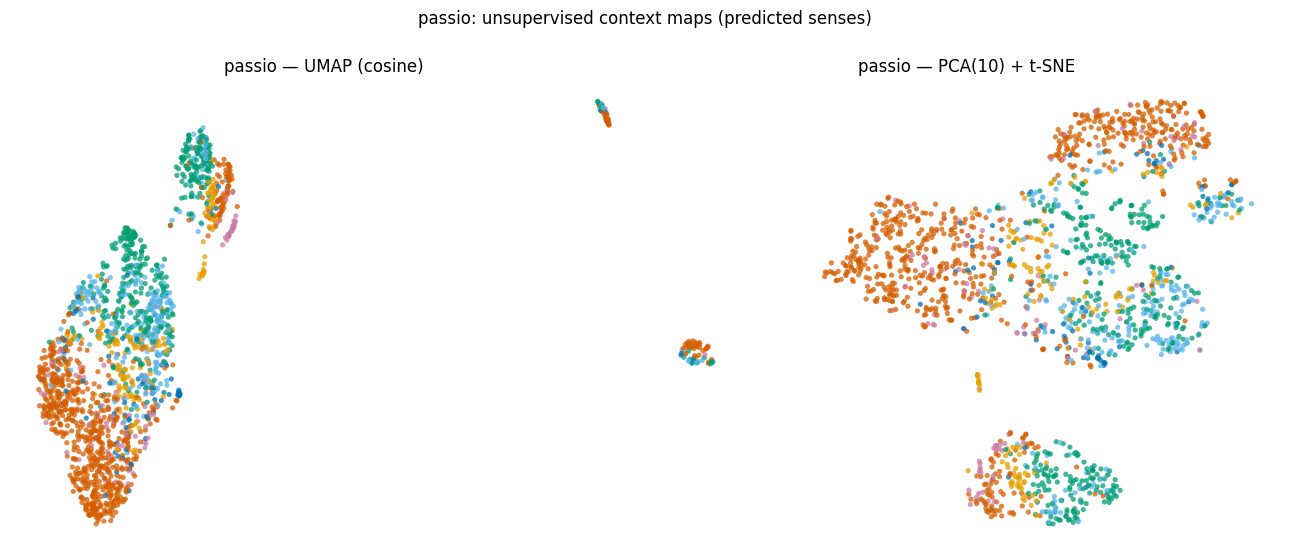

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


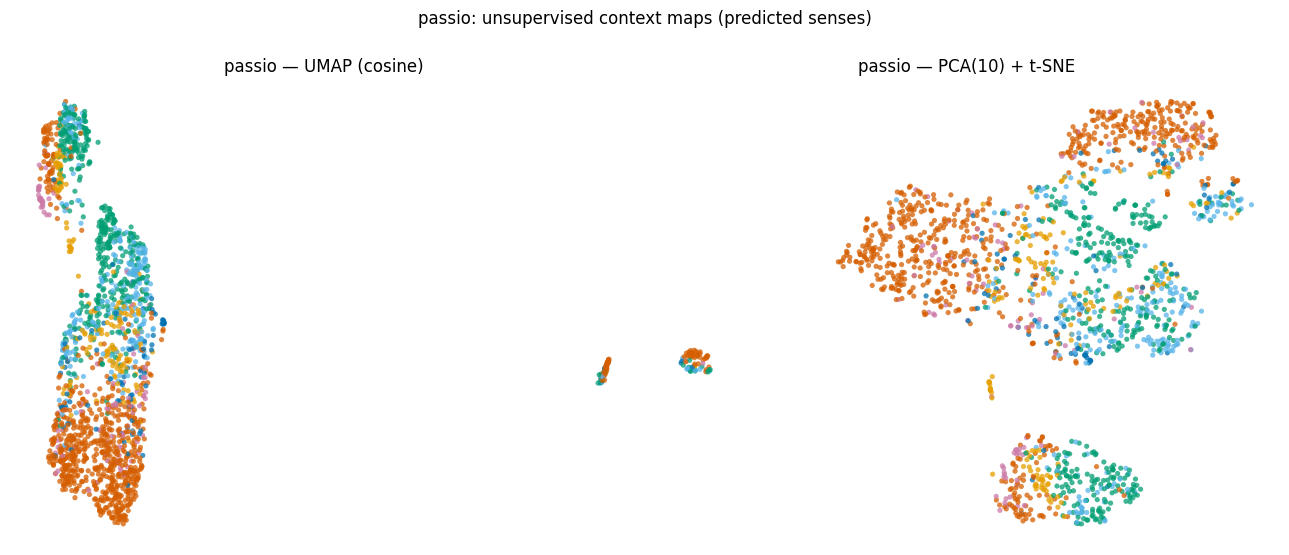

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


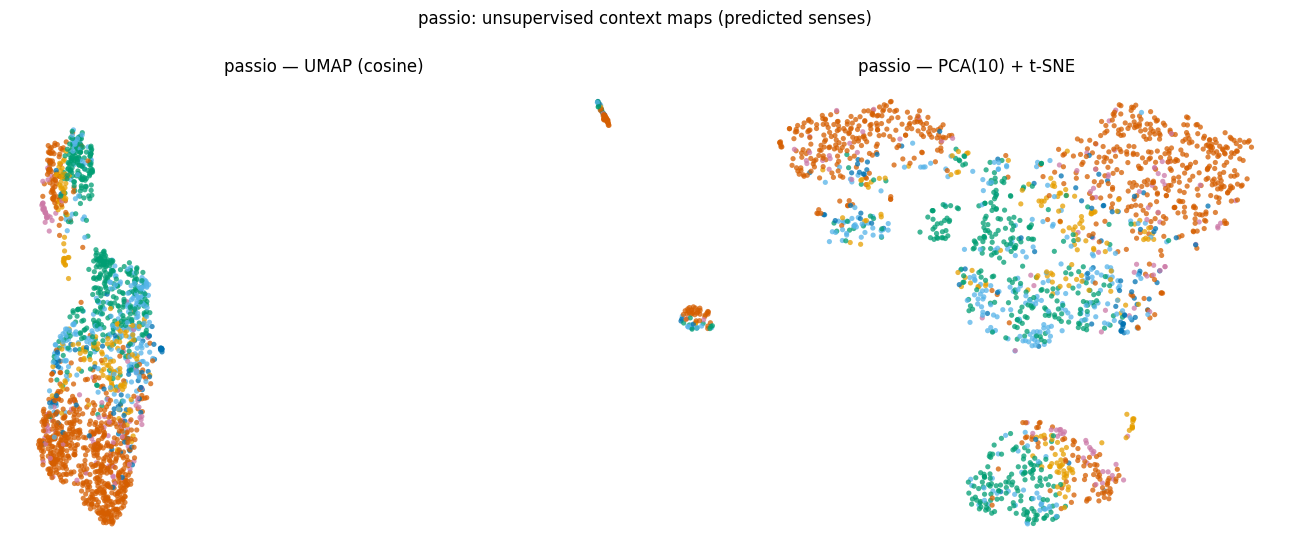

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


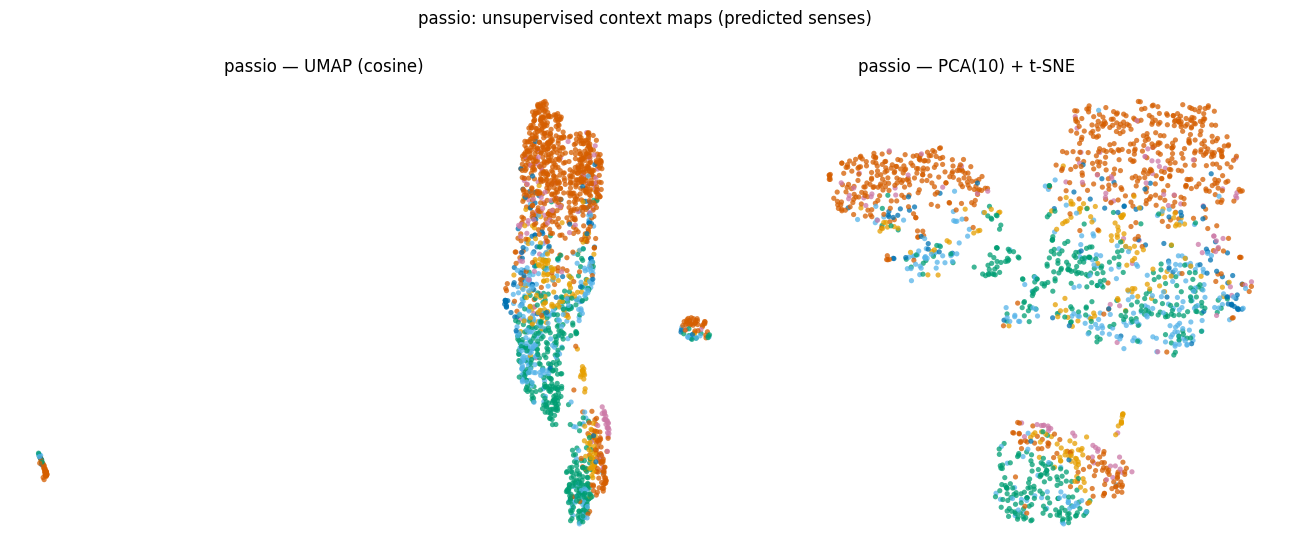

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


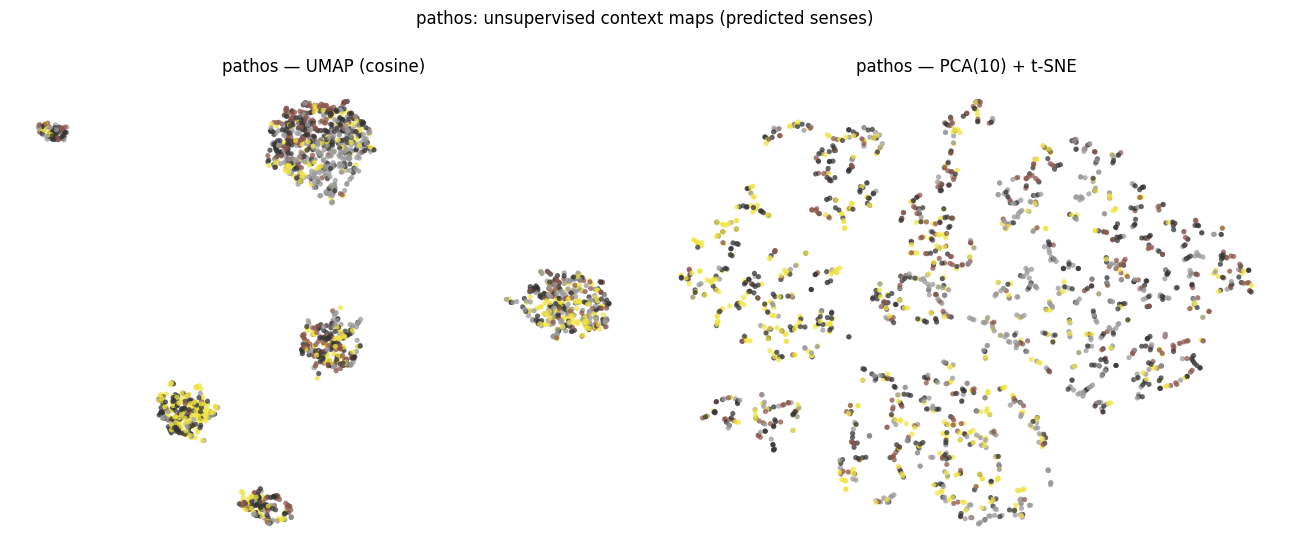

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


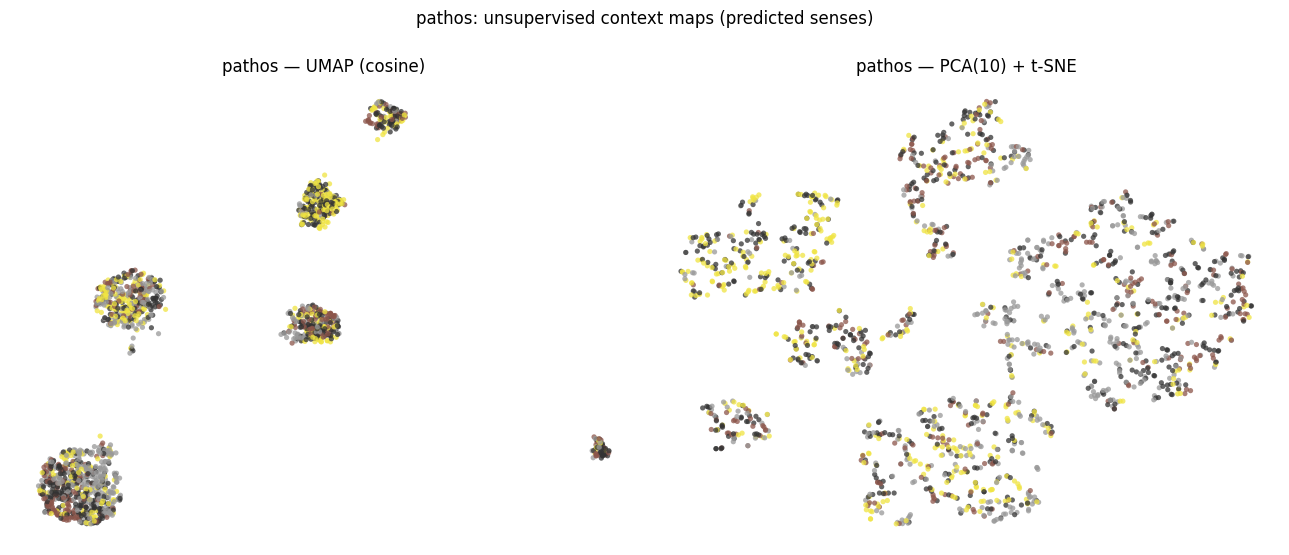

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


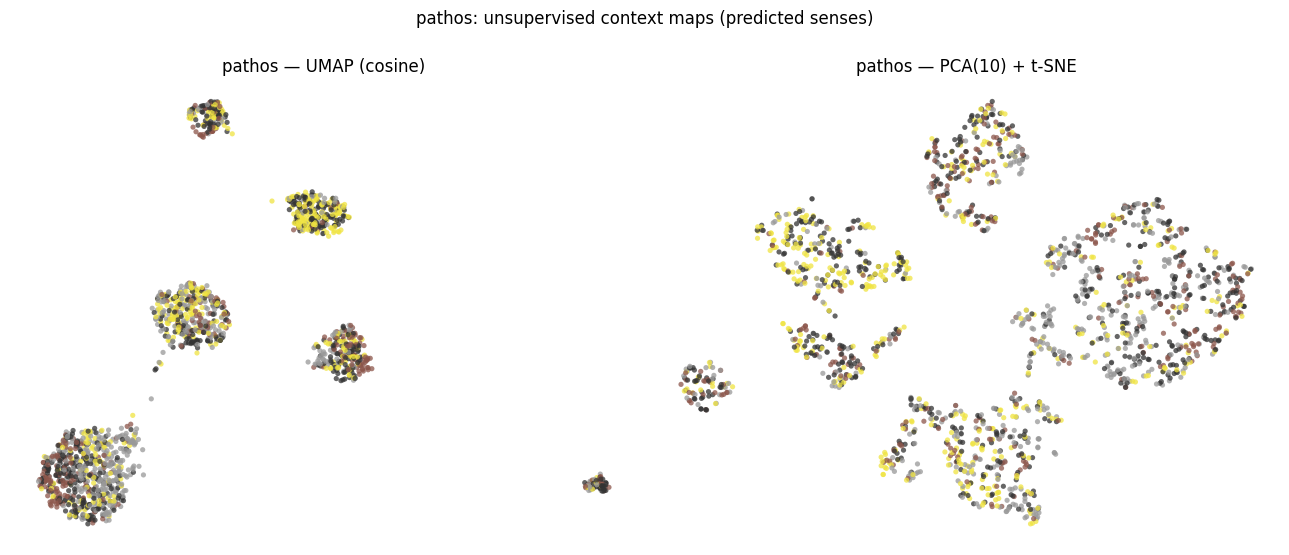

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


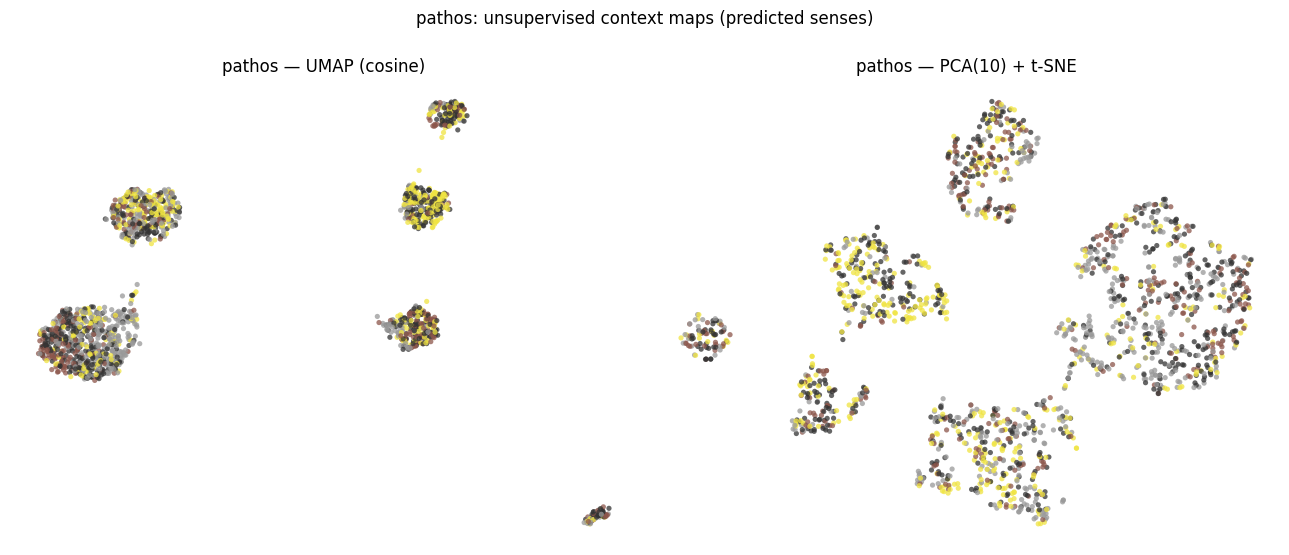

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


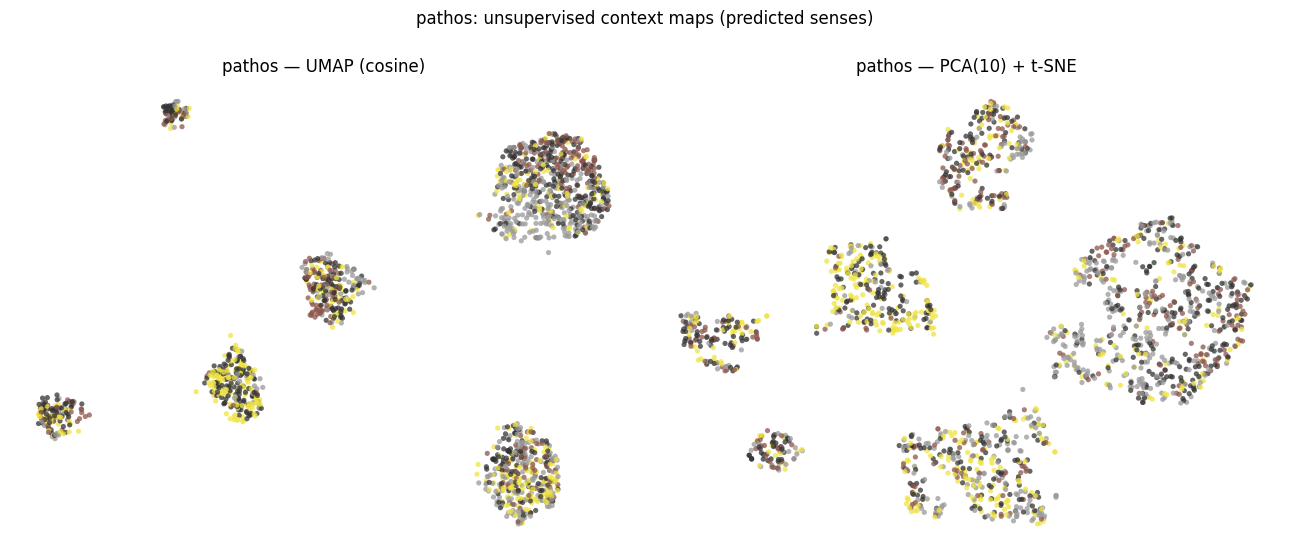

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


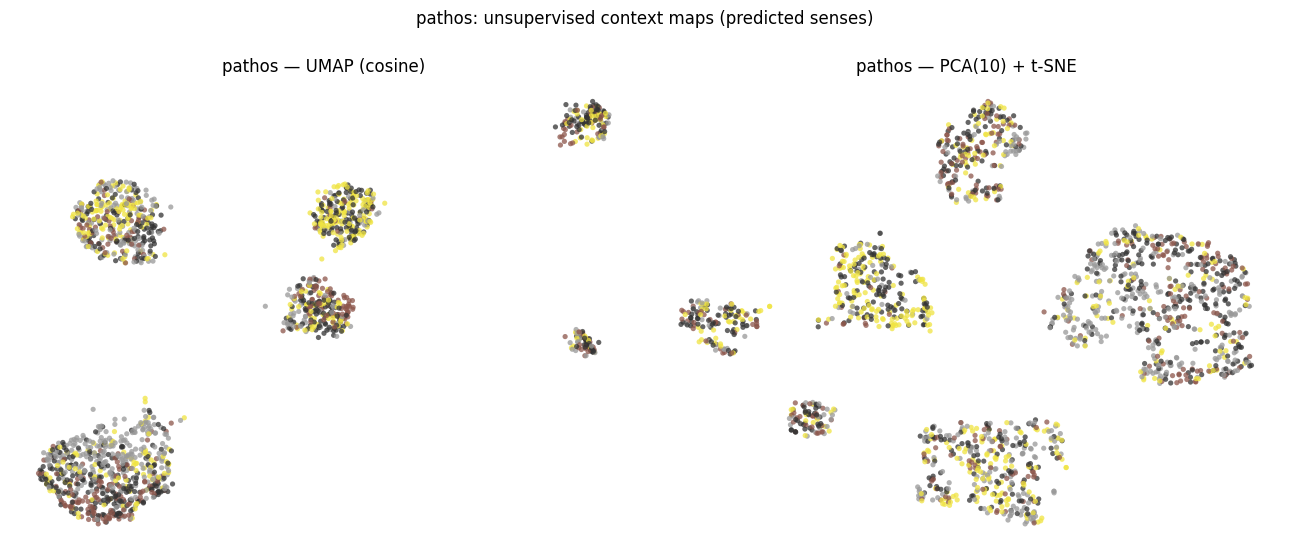

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


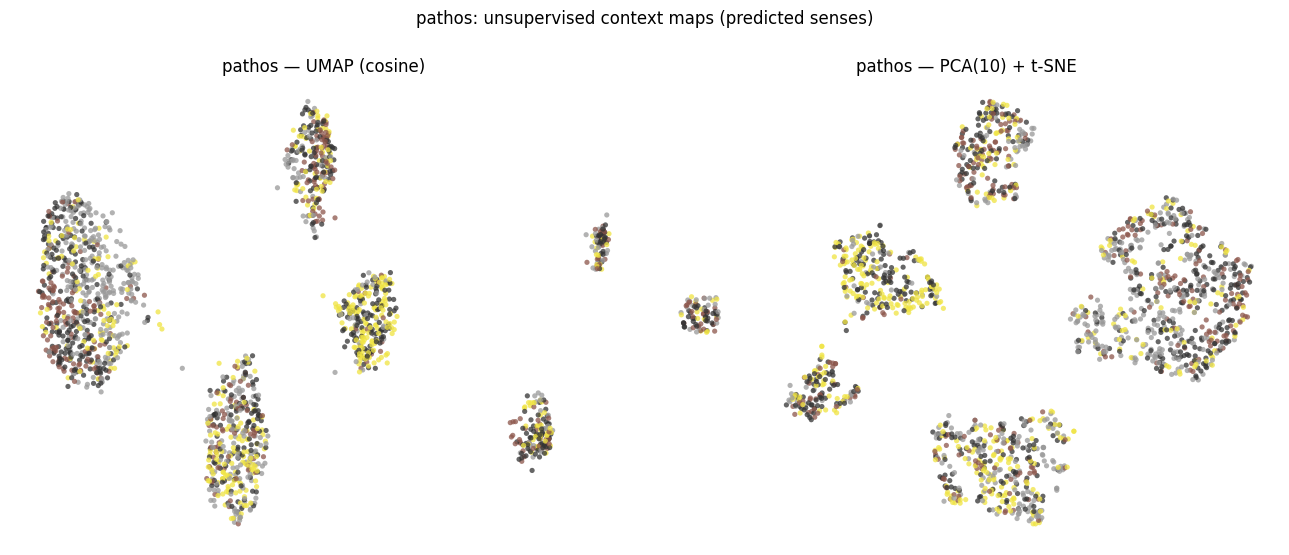

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


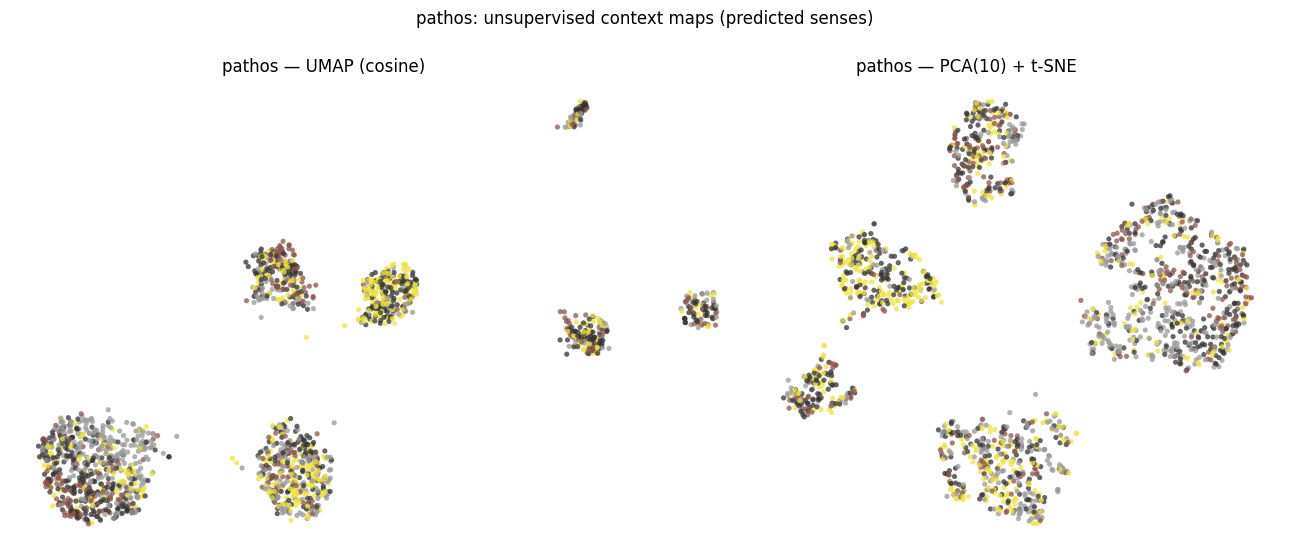

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


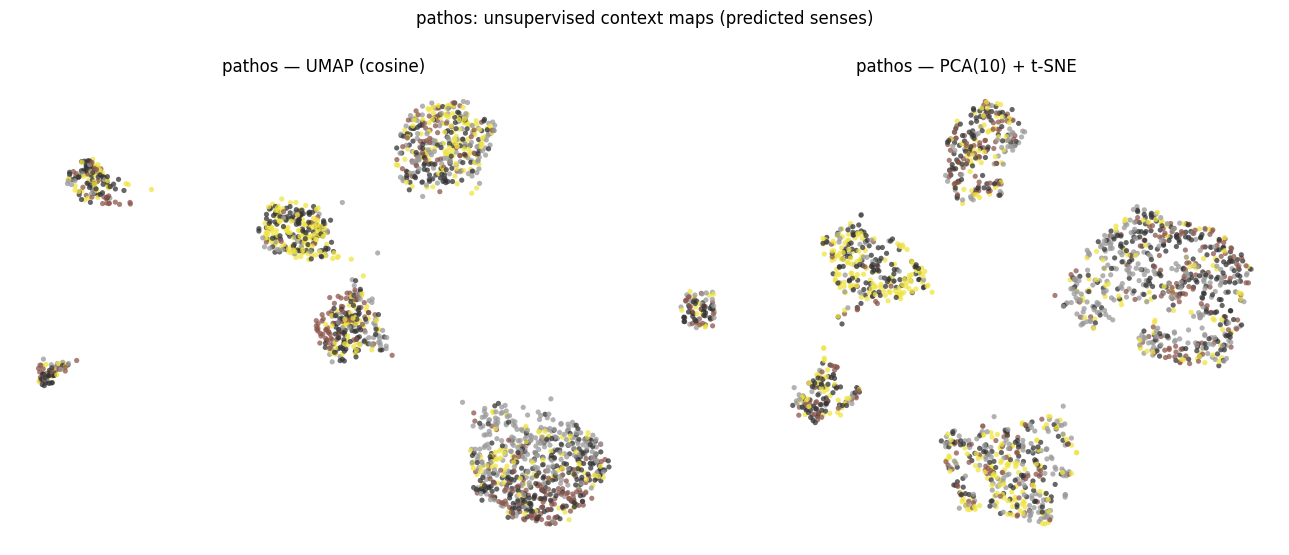

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


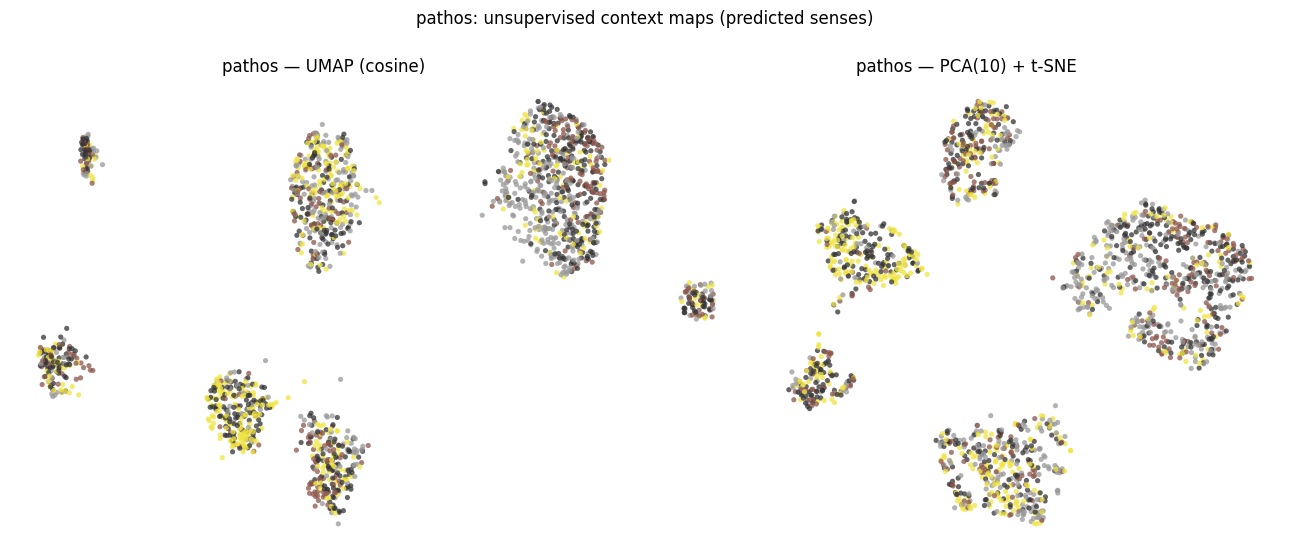

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


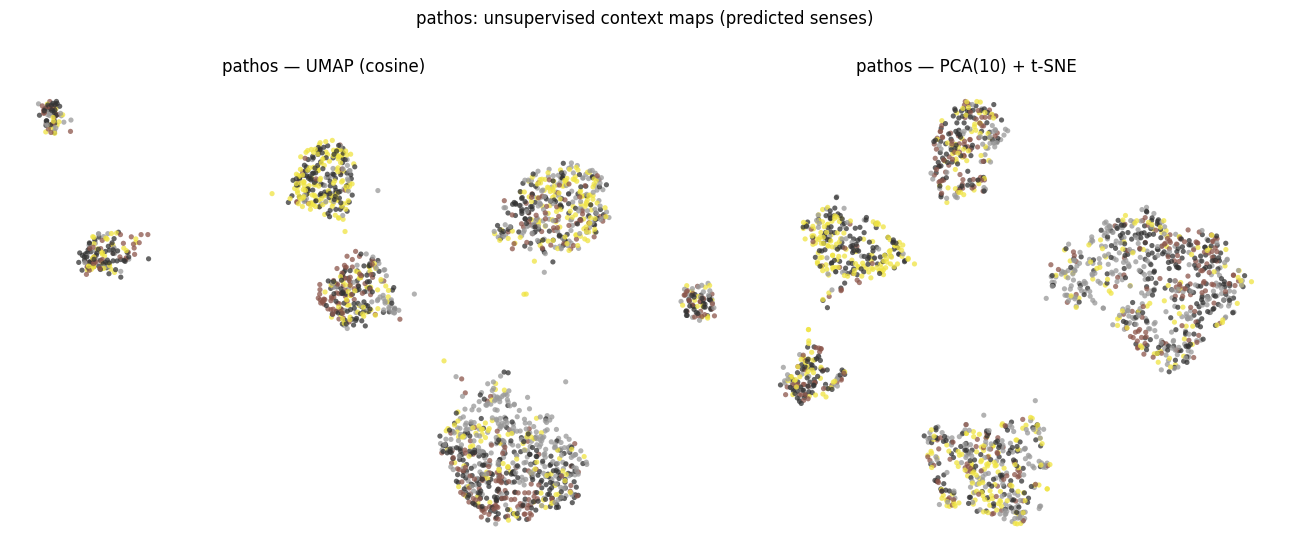

In [6]:
def context_maps(term, umap_neigh=15, perplexity=30):
    X, y = SAMPLE[term]["X"], SAMPLE[term]["y"]
    Xs, ys, _ = subsample(X, y)
    maps = {
        "UMAP (cosine)": umap.UMAP(n_neighbors=umap_neigh, min_dist=0.1, metric="cosine",
                                   random_state=SEED).fit_transform(Xs),
        "PCA(10) + t-SNE": TSNE(2, perplexity=perplexity, init="pca", random_state=SEED)
                             .fit_transform(PCA(n_components=10, random_state=SEED).fit_transform(Xs)),
    }
    palette = SENSE_PALETTE[term]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, (name, Z) in zip(axes, maps.items()):
        ax.scatter(Z[:, 0], Z[:, 1], c=[palette[v] for v in ys],
                   s=14, alpha=0.75, linewidths=0)
        ax.set_title(f"{term} — {name}"); ax.axis("off")
    fig.suptitle(f"{term}: unsupervised context maps (predicted senses)", y=1.0)
    fig.tight_layout()
    fig.savefig(FIGDIR / f"{term}_context_maps.png", dpi=150, bbox_inches="tight")
    plt.show()




for term in TERMS:
    for n in range(5,60,5):
        context_maps(term, umap_neigh=n, perplexity=n)

/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


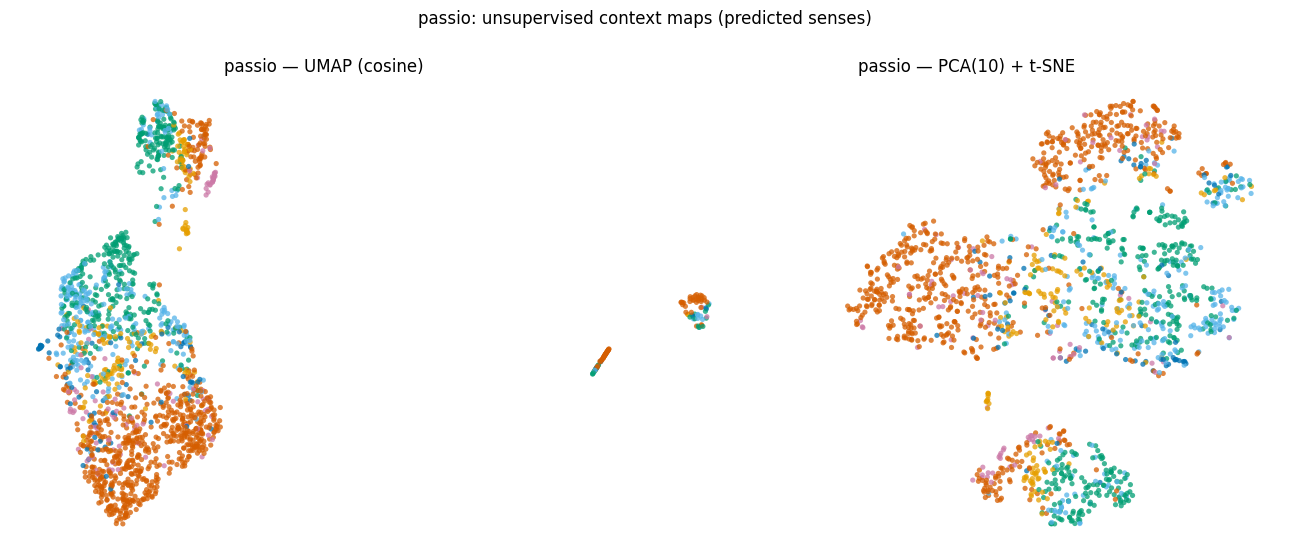

In [8]:
n = 30
term = "passio"
context_maps(term, umap_neigh=n, perplexity=n)

## 6. Sense discrimination — supervised LDA (sample)

Sharpest view, but the most circular (it uses the labels to choose the axes).

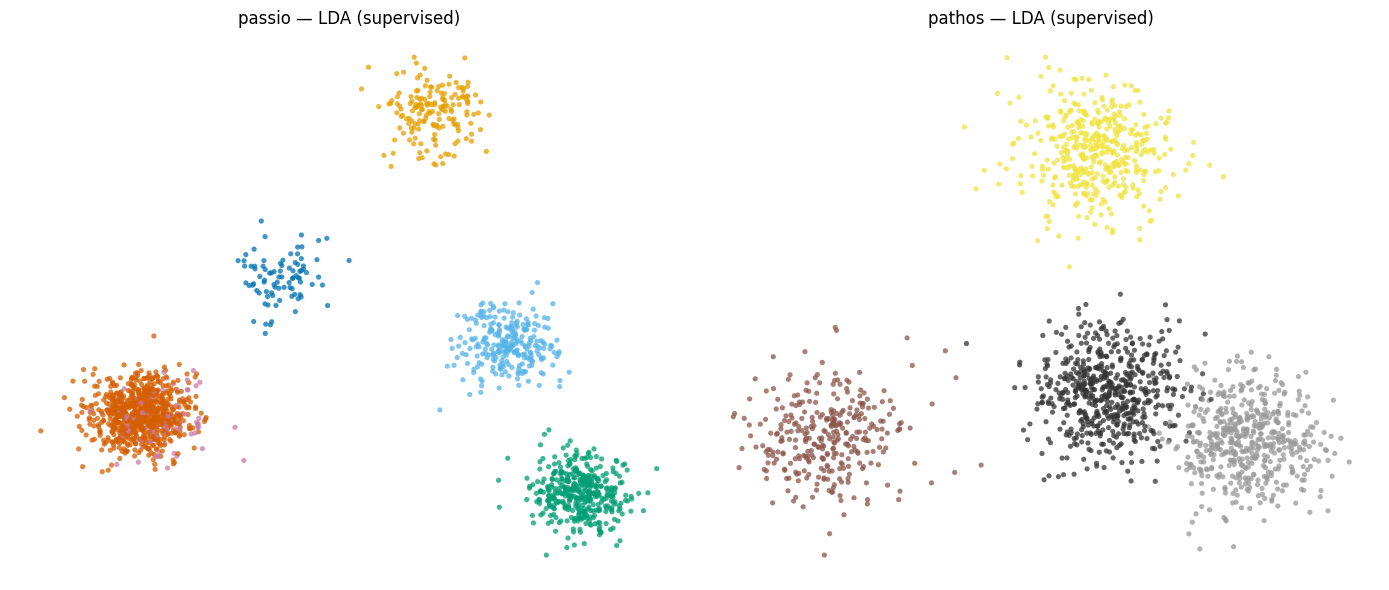

In [9]:
from lda_projections import compute_lda_projection

fig, axes = plt.subplots(1, len(TERMS), figsize=(7 * len(TERMS), 6))
for ax, term in zip(np.atleast_1d(axes), TERMS):
    X, y = SAMPLE[term]["X"], SAMPLE[term]["y"]
    Z, _ = compute_lda_projection(X, y)
    palette = SENSE_PALETTE[term]
    ax.scatter(Z[:, 0], Z[:, 1], c=[palette[v] for v in y], s=14, alpha=0.75, linewidths=0)
    ax.set_title(f"{term} — LDA (supervised)"); ax.axis("off")
fig.tight_layout()
fig.savefig(FIGDIR / "lda_views.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Diachronic composition (full)

No embedding required: the share of each predicted sense per century — a robust first look at lineage before any projection.

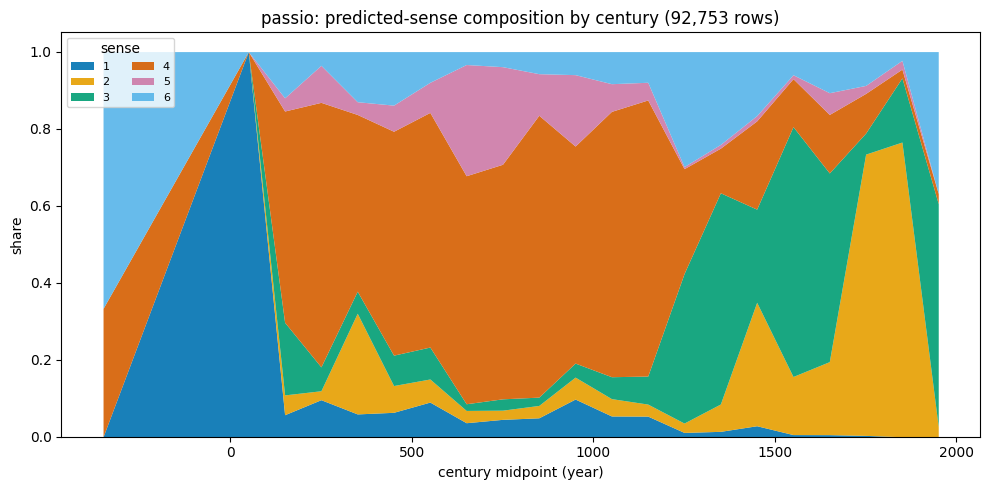

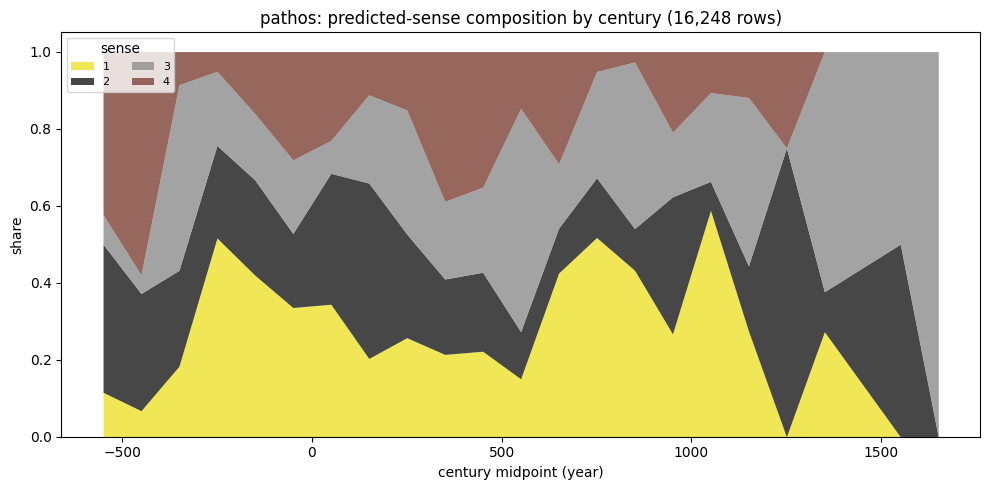

In [10]:
RICH = VARIANTS.get("full", VARIANTS["sample"])

for term in TERMS:
    df = RICH[term]["df"].dropna(subset=["century"])
    counts = df.groupby(["century", "sense"]).size().unstack(fill_value=0).sort_index()
    share = counts.div(counts.sum(axis=1), axis=0)
    colors = [SENSE_PALETTE[term][s] for s in share.columns]
    ax = share.plot.area(figsize=(10, 5), color=colors, alpha=0.9, linewidth=0)
    ax.set_title(f"{term}: predicted-sense composition by century ({len(df):,} rows)")
    ax.set_xlabel("century midpoint (year)"); ax.set_ylabel("share")
    ax.legend(loc="upper left", fontsize=8, ncol=2, title="sense")
    plt.tight_layout()
    plt.savefig(FIGDIR / f"{term}_century_composition.png", dpi=150, bbox_inches="tight")
    plt.show()

## 8. Lineage — century centroids → trajectories (**both variants**)

Project **all** points to 2D, average coordinates per `(sense, century)`, connect
consecutive valid centuries, time on Z. `LINEAGE_SPACE = "lda"` (supervised) or `"umap"`.
Rendered once per variant (sample and full).

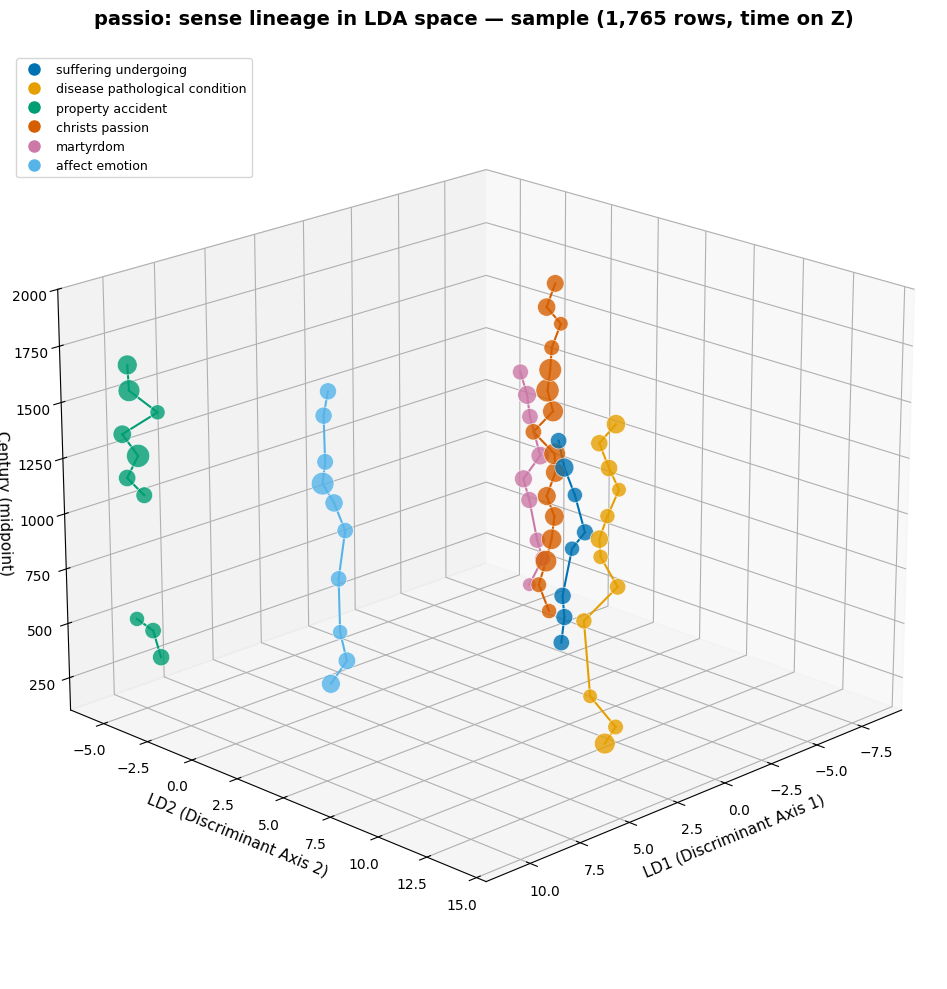

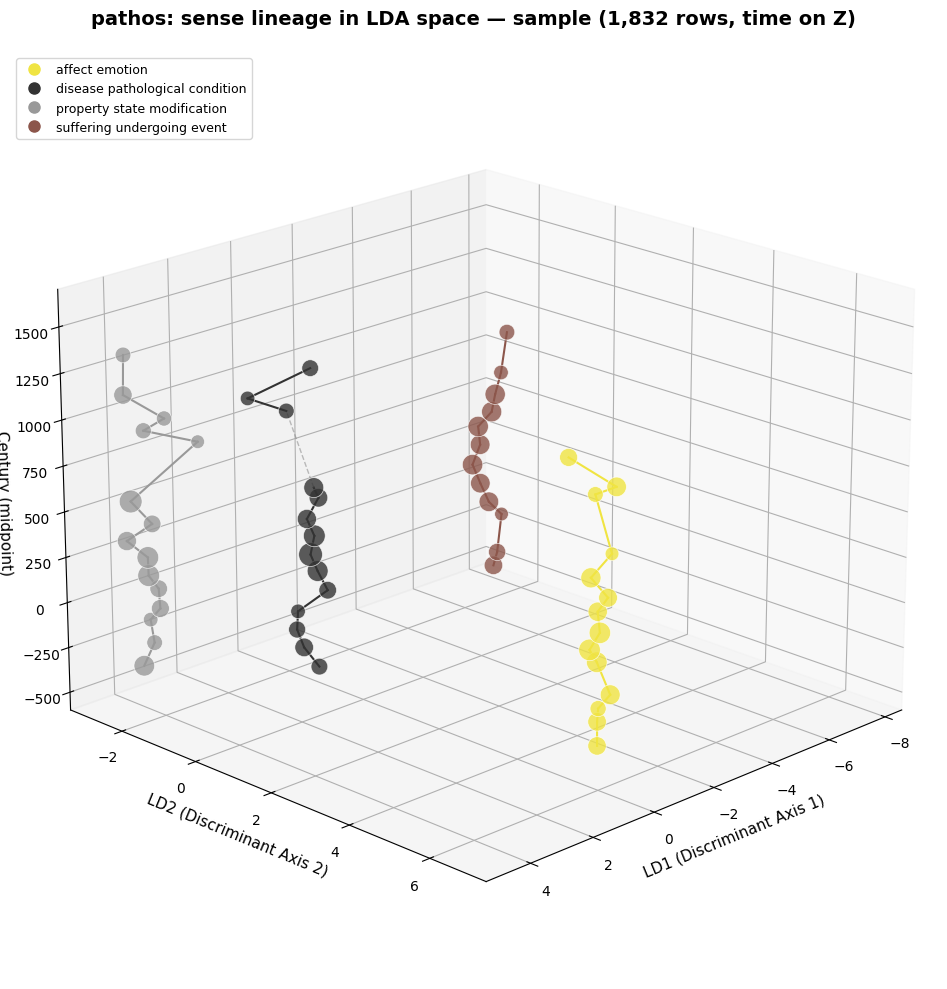

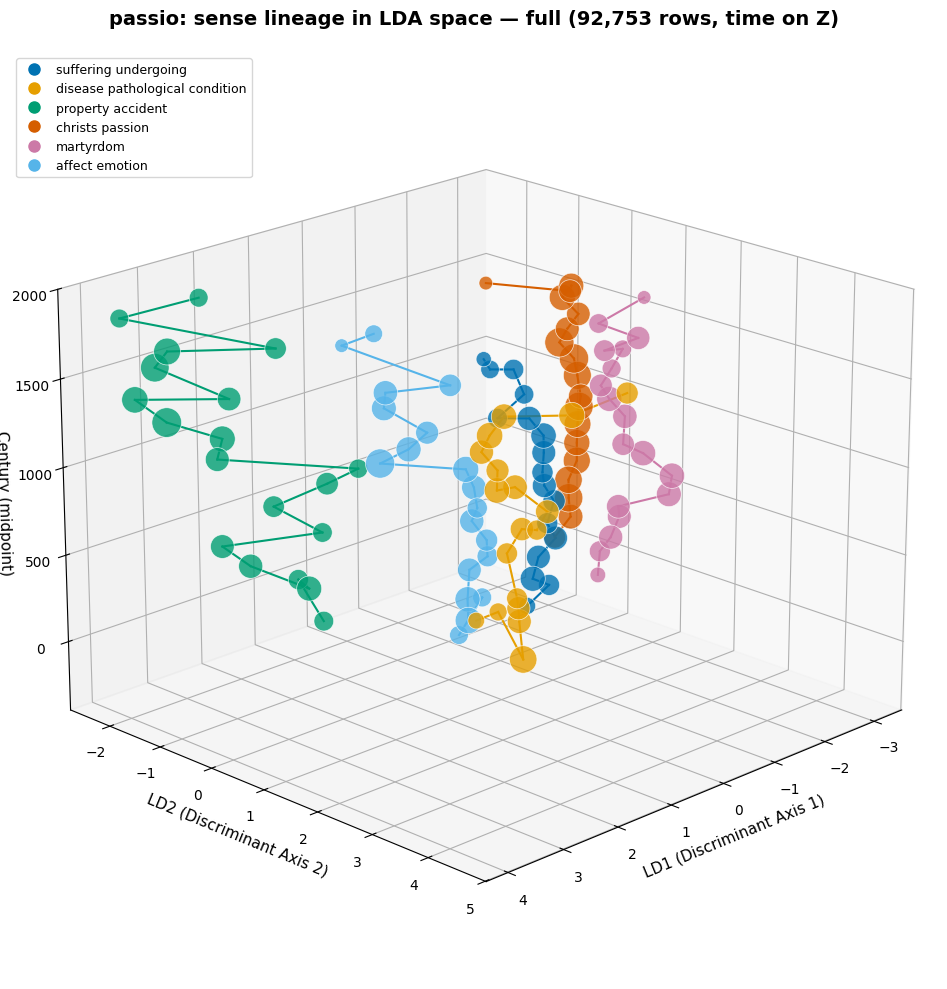

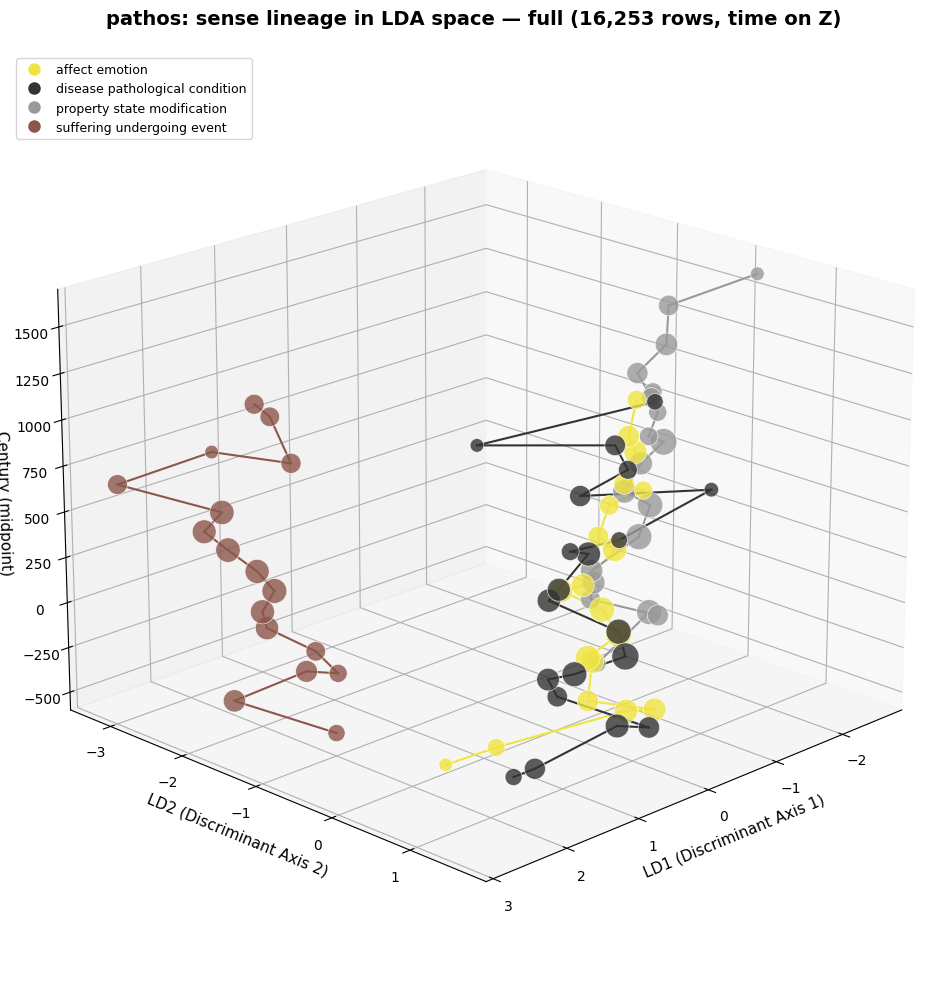

In [11]:
from projections_helpers import plot_3d_century_trajectories

LINEAGE_SPACE = "lda"   # "lda" (supervised) or "umap" (unsupervised)


def project_2d(variant, term, space):
    X, y = variant[term]["X"], variant[term]["y"]
    if space == "lda":
        return compute_lda_projection(X, y)[0]
    Xs, ys, idx = subsample(X, y)              # UMAP has no exact transform
    Zs = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                   random_state=SEED).fit_transform(Xs)
    Z = np.full((len(X), 2), np.nan)
    Z[idx] = Zs
    return Z


def build_trajectories(df, Z2, min_samples=MIN_CENTURY_SAMPLES):
    """Centroid of each (sense, century) in 2-D projection space."""
    d = df.assign(x2=Z2[:, 0], y2=Z2[:, 1]).dropna(subset=["x2", "century"])
    traj = {}
    for sense, g in d.groupby("sense"):
        rows = sorted(
            (int(c), float(gg["x2"].mean()), float(gg["y2"].mean()), len(gg))
            for c, gg in g.groupby("century")
        )
        traj[int(sense)] = {
            "centuries": [r[0] for r in rows],
            "x": [r[1] for r in rows],
            "y": [r[2] for r in rows],
            "z": [r[0] for r in rows],
            "sample_counts": [r[3] for r in rows],
            "marker_sizes": [50 + 100 * np.log10(max(r[3], 1)) for r in rows],
            "is_valid": [r[3] >= min_samples for r in rows],
        }
    return traj


for vname, v in VARIANTS.items():
    for term in TERMS:
        Z2 = project_2d(v, term, LINEAGE_SPACE)
        traj = build_trajectories(v[term]["df"], Z2)
        fig = plot_3d_century_trajectories(
            trajectory_data=traj, label_names=SENSE_NAMES[term],
            palette=SENSE_PALETTE[term],
            title=f"{term}: sense lineage in {LINEAGE_SPACE.upper()} space — {vname} "
                  f"({len(v[term]['df']):,} rows, time on Z)",
            interpolate_gaps=True, max_gap_centuries=2,
        )
        fig.savefig(FIGDIR / f"{term}_lineage_{LINEAGE_SPACE}_{vname}.png",
                    dpi=200, bbox_inches="tight")
        plt.show()

## 9. Curated ERC B1 figure — **sample only**

Three 3-D panels per lexeme, time on Z:

- **A** contextual usages — unsupervised PCA + t-SNE + time
- **B** sense discrimination — supervised LDA + time
- **C** diachronic trajectories — century centroids in **B's** LDA basis

Point clouds use the **sample** (dots look best with the 2 000-point set); centroid
trajectories in C reuse the same LDA basis as B, so B and C share x/y extents.

In [12]:
names, palette = SENSE_NAMES[term], SENSE_PALETTE[term]


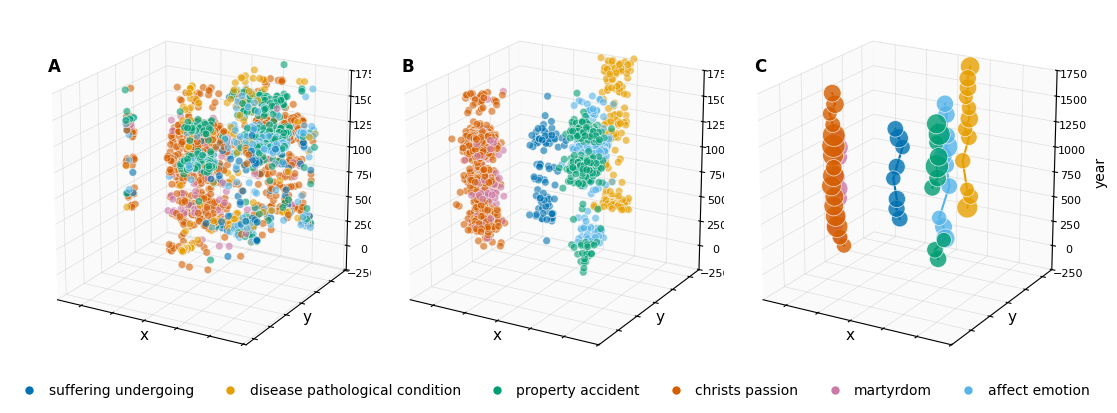

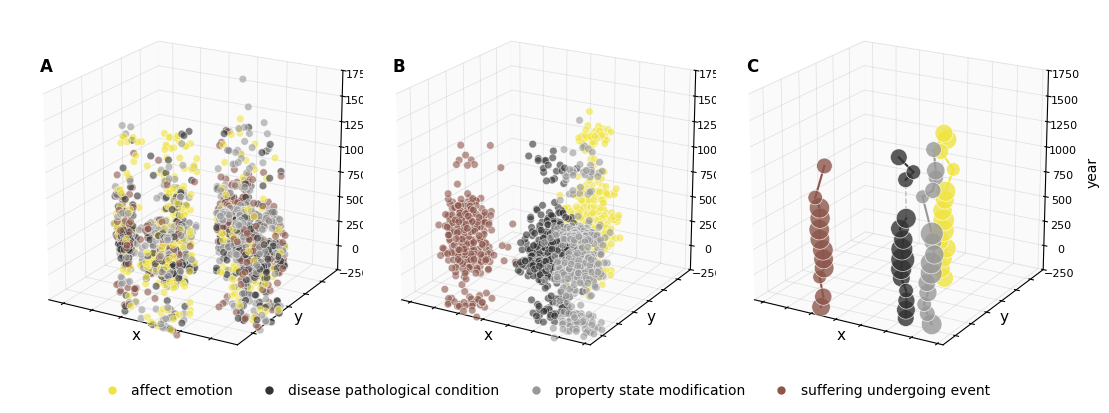

In [31]:
from matplotlib.lines import Line2D
from projections_helpers import (
    plot_3d_lda_temporal,
    plot_3d_century_trajectories,
)


def erc_figure(term, variant=SAMPLE, save=True):
    df, X, y = variant[term]["df"], variant[term]["X"], variant[term]["y"]
    names, palette = SENSE_NAMES[term], SENSE_PALETTE[term]

    X_lda_all = compute_lda_projection(X, y)[0]
    traj = build_trajectories(df, X_lda_all)

    n = len(X)
    idx = (
        np.random.default_rng(SEED).choice(n, FIG_CAP, replace=False)
        if n > FIG_CAP else np.arange(n)
    )
    dates = df["random_date"].values

    X_unsup = TSNE(
        2, perplexity=30, init="pca", random_state=SEED
    ).fit_transform(
        PCA(n_components=10, random_state=SEED).fit_transform(X[idx])
    )

    fig = plt.figure(figsize=(12, 4))

    ax_a = fig.add_subplot(1, 3, 1, projection="3d")
    plot_3d_lda_temporal(
        X_lda=X_unsup,
        dates=dates[idx],
        labels=y[idx],
        label_names=names,
        palette=palette,
        title="A",
        ax=ax_a,
        show_legend=False,
        elev=ELEV,
        azim=AZIM,
    )

    ax_b = fig.add_subplot(1, 3, 2, projection="3d")
    plot_3d_lda_temporal(
        X_lda=X_lda_all[idx],
        dates=dates[idx],
        labels=y[idx],
        label_names=names,
        palette=palette,
        title="B",
        ax=ax_b,
        show_legend=False,
        elev=ELEV,
        azim=AZIM,
    )

    ax_c = fig.add_subplot(1, 3, 3, projection="3d")
    plot_3d_century_trajectories(
        trajectory_data=traj,
        label_names=names,
        palette=palette,
        ax=ax_c,
        show_legend=False,
        elev=ELEV,
        azim=AZIM,
        title="C",
    )

    sx = (
        min(ax_b.get_xlim()[0], ax_c.get_xlim()[0]),
        max(ax_b.get_xlim()[1], ax_c.get_xlim()[1]),
    )
    sy = (
        min(ax_b.get_ylim()[0], ax_c.get_ylim()[0]),
        max(ax_b.get_ylim()[1], ax_c.get_ylim()[1]),
    )
    for ax in (ax_b, ax_c):
        ax.set_xlim(sx)
        ax.set_ylim(sy)

    for ax in (ax_a, ax_b, ax_c):
        ax.view_init(elev=ELEV, azim=AZIM)
        ax.set_box_aspect((1, 1, 1))
        ax.set_zlim(-250, 1750)

        ax.set_xlabel("x", labelpad=-15)
        ax.set_ylabel("y", labelpad=-15)
        ax.xaxis.label.set_visible(True)
        ax.yaxis.label.set_visible(True)

        # Replace the native z-label with explicitly positioned text.
        ax.set_zlabel("")
        ax.text2D(
            1.04, 0.55, "year",
            transform=ax.transAxes,
            rotation=90,
            ha="center",
            va="center",
            fontsize=10,
            clip_on=False,
        )

        # Retain the grid while hiding x/y tick labels.
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.tick_params(axis="z", labelsize=8, pad=0)
        ax.grid(True)

        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
            axis._axinfo["grid"]["color"] = (0.75, 0.75, 0.75, 0.45)
            axis._axinfo["grid"]["linewidth"] = 0.5
            axis.set_pane_color((0.97, 0.97, 0.97, 0.50))

        ax.set_title(
            ax.get_title(),
            fontsize=12,
            fontweight="bold",
            x=0.1,
            y=0.9,
            pad=0,
        )

    handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            markeredgecolor="none",
            markerfacecolor=palette[lid],
            label=names[lid],
            markersize=6,
        )
        for lid in sorted(names)
    ]

    fig.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=min(len(names), 6),
        frameon=False,
        fontsize=10,
        columnspacing=1.6,
        handletextpad=0.4,
        borderaxespad=0,
    )

    fig.subplots_adjust(
        left=0.01,
        right=0.99,
        bottom=0.085,
        top=0.99,
        wspace=-0.25,
    )

    if save:
        fig.savefig(
            FIGDIR / f"{term}_erc_ABC_sample.png",
            dpi=200,
            bbox_inches="tight",
        )

    plt.show()
    return fig


for term in TERMS:
    erc_figure(term)

## 10. Shared semantic space from within-lexeme LDA directions

We fit LDA separately for passio and pathos using their existing inventories, then
concatenate the complete loading matrices. Every occurrence of either word is projected
through **both sets of directions**. Each loading matrix has equal total squared weight.
No emotion labels are merged and no cross-language sense correspondence is supplied.

A label-free covariance rotation chooses two display axes from these common scores.
The covariance averages within-word variation with equal word weights, so differing
word means do not determine the display axes. The transformation itself uses a **single
shared origin**, preserving offsets between the words. This amplifies within-language
sense information; it does not guarantee overlap or establish bilingual alignment.

By default fit the basis on the LLM-labelled **sample**, and apply the same frozen basis
to sample and full data. This avoids learning a new projection from the full classifier
predictions. All original embedding dimensions and all local discriminants are retained
before the final two-dimensional display reduction.

In [40]:
import importlib
import lda_projections
importlib.reload(lda_projections)
from lda_projections import compute_within_lexeme_shared_projection
from projections_helpers import compute_century_trajectories_data, plot_3d_century_trajectories
from matplotlib.lines import Line2D
from sklearn.metrics.pairwise import euclidean_distances
from threadpoolctl import threadpool_limits
from IPython.display import display

WITHIN_SHARED_FIT_VARIANT = "sample"  # optionally "full"; sample is the default
WITHIN_SHARED_ELEV, WITHIN_SHARED_AZIM = 35, -60
WITHIN_SHARED_MARKERS = {"passio": "o", "pathos": "x"}
WITHIN_SHARED_TERMS = ["passio", "pathos"]
WITHIN_SHARED_MIN_CENTURY = 3

fit_variant = VARIANTS[WITHIN_SHARED_FIT_VARIANT]
fit_X = {t: fit_variant[t]["X"] for t in WITHIN_SHARED_TERMS}
fit_y = {t: fit_variant[t]["y"] for t in WITHIN_SHARED_TERMS}
with threadpool_limits(limits=2):
    _, WITHIN_SHARED_MODEL = compute_within_lexeme_shared_projection(fit_X, fit_y)
print("Fitted on:", WITHIN_SHARED_FIT_VARIANT)
print("Local discriminant counts:", {
    t: len(m.explained_variance_ratio_) for t, m in WITHIN_SHARED_MODEL.local_models_.items()})
print("Combined loading shape:", WITHIN_SHARED_MODEL.directions_.shape)
print("Fraction of within-word score variance shown:",
      round(float(WITHIN_SHARED_MODEL.explained_variance_ratio_[:2].sum()), 3))

Fitted on: sample
Local discriminant counts: {'passio': 5, 'pathos': 3}
Combined loading shape: (1536, 8)
Fraction of within-word score variance shown: 0.41


### Shared sense map and distances before/after the 2-D reduction

All senses participate equally in the interpretation; the projection does not select
emotion specifically. The two tables show cross-word centroid distances in the complete
combined score space and in the display space. Compare rankings **within each table**,
not absolute distances across spaces. Emotion proximity, if present, is an outcome.
The map uses the labelled sample; sample century trajectories below reuse exactly the same model.

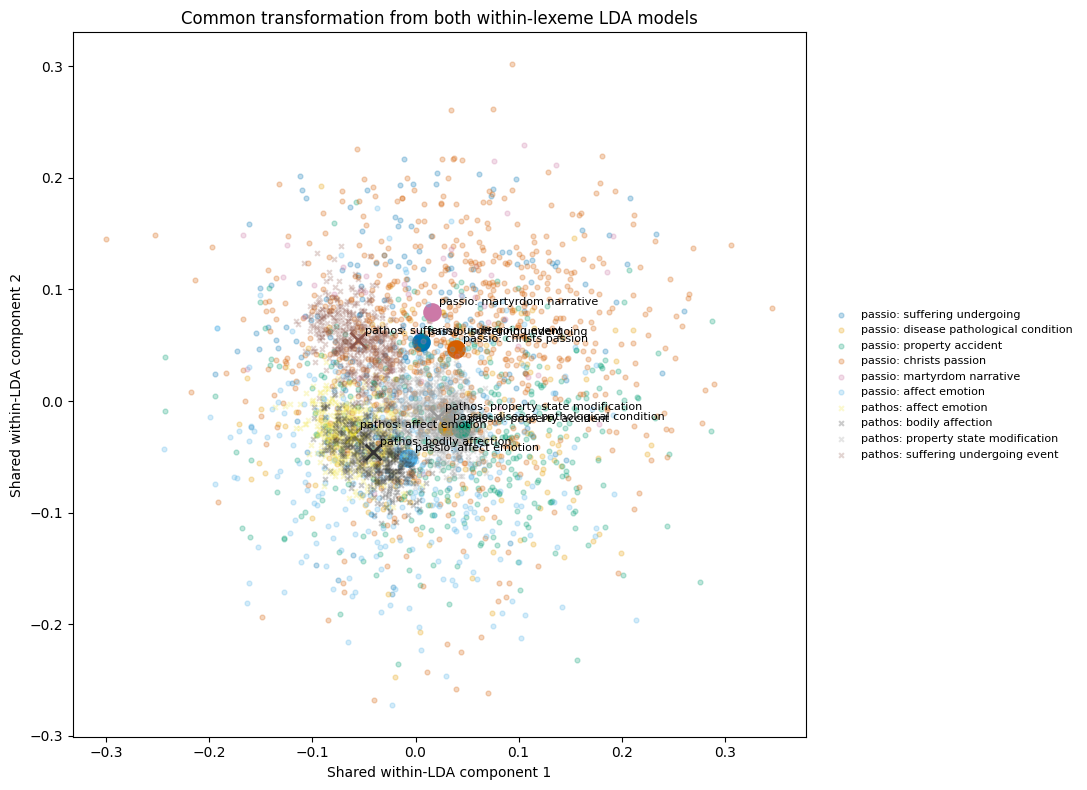

all discriminant scores


,pathos: affect emotion,pathos: bodily affection,pathos: property state modification,pathos: suffering undergoing event
passio: suffering undergoing,0.1738,0.2258,0.1840,0.1806
passio: disease pathological condition,0.1538,0.1565,0.1361,0.1735
passio: property accident,0.1255,0.1435,0.0893,0.1526
passio: christs passion,0.1870,0.2265,0.1751,0.1872
passio: martyrdom narrative,0.2067,0.2311,0.1926,0.1903
passio: affect emotion,0.1180,0.1806,0.1465,0.1837


2-D display


,pathos: affect emotion,pathos: bodily affection,pathos: property state modification,pathos: suffering undergoing event
passio: suffering undergoing,0.1066,0.1092,0.0697,0.0613
passio: disease pathological condition,0.0910,0.0749,0.0119,0.1160
passio: property accident,0.1053,0.0884,0.0247,0.1281
passio: christs passion,0.1267,0.1230,0.0638,0.0959
passio: martyrdom narrative,0.1347,0.1382,0.0948,0.0764
passio: affect emotion,0.0568,0.0343,0.0469,0.1159


In [41]:
WITHIN_SHARED_COORDS = {
    name: {t: WITHIN_SHARED_MODEL.transform(v[t]["X"]) for t in WITHIN_SHARED_TERMS}
    for name, v in VARIANTS.items()}
map_variant = VARIANTS["sample"]
fig, ax = plt.subplots(figsize=(11, 8))
within_centroids = {"all discriminant scores": {}, "2-D display": {}}
for t in WITHIN_SHARED_TERMS:
    X, y = map_variant[t]["X"], np.asarray(map_variant[t]["y"])
    Z = WITHIN_SHARED_COORDS["sample"][t]
    # Transform sense means directly: exactly equal to means of transformed usages.
    ids = sorted(np.unique(y))
    means = np.stack([X[y == s].mean(axis=0) for s in ids])
    within_centroids["all discriminant scores"][t] = (ids, WITHIN_SHARED_MODEL.transform_discriminant_space(means))
    within_centroids["2-D display"][t] = (ids, WITHIN_SHARED_MODEL.transform(means))
    for s, c in zip(ids, within_centroids["2-D display"][t][1]):
        points = Z[y == s]
        ax.scatter(points[:, 0], points[:, 1], marker=WITHIN_SHARED_MARKERS[t],
                   color=SENSE_PALETTE[t][s], s=12, alpha=.25,
                   label=f"{t}: {SENSE_NAMES[t][s]}")
        ax.scatter(*c, marker=WITHIN_SHARED_MARKERS[t], color=SENSE_PALETTE[t][s], s=130, linewidths=2)
        ax.annotate(f"{t}: {SENSE_NAMES[t][s]}", c, xytext=(5, 5),
                    textcoords="offset points", fontsize=8)
ax.set_xlabel("Shared within-LDA component 1"); ax.set_ylabel("Shared within-LDA component 2")
ax.set_title("Common transformation from both within-lexeme LDA models")
ax.legend(loc="center left", bbox_to_anchor=(1.02, .5), frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "within_lda_shared_sense_map.png", dpi=200, bbox_inches="tight")
plt.show()
WITHIN_SHARED_DISTANCE_TABLES = {}
for space, centroids in within_centroids.items():
    pids, pc = centroids["passio"]; gids, gc = centroids["pathos"]
    table = pd.DataFrame(euclidean_distances(pc, gc),
        index=[f"passio: {SENSE_NAMES['passio'][s]}" for s in pids],
        columns=[f"pathos: {SENSE_NAMES['pathos'][s]}" for s in gids])
    WITHIN_SHARED_DISTANCE_TABLES[space] = table
    print(space); display(table.round(4))

### Shared century-centroid trajectories — labelled sample

Use the labelled **sample** for both words, projected through the same fitted shared
transformation as the sense map above. Each marker is the mean of the actual usages
for one sense in one century, plotted at the existing BCE-safe century midpoint.
Centroids require at least `WITHIN_SHARED_MIN_CENTURY` usages (default: 3).
Lines connect consecutive valid centuries; missing or under-threshold centuries leave
gaps. Counts and distinct-work counts are shown below for inspection.
These trajectories describe usage centroids, not descent relationships.


passio (sample): 87 populated sense-century bins; 68 have at least 3 usages


,sense,year,n,n_works,valid
0,1,250.0,1,1,False
1,1,350.0,12,10,True
2,1,450.0,7,7,True
3,1,550.0,10,4,True
4,1,650.0,3,3,True
...,...,...,...,...,...
82,6,1350.0,12,5,True
83,6,1450.0,2,2,False
84,6,1550.0,8,7,True
85,6,1650.0,13,9,True


pathos (sample): 70 populated sense-century bins; 53 have at least 3 usages


,sense,year,n,n_works,valid
0,1,-550.0,1,1,False
1,1,-450.0,1,1,False
2,1,-350.0,19,11,True
3,1,-250.0,18,3,True
4,1,-150.0,5,1,True
...,...,...,...,...,...
65,4,650.0,5,3,True
66,4,750.0,1,1,False
67,4,950.0,6,1,True
68,4,1050.0,2,2,False


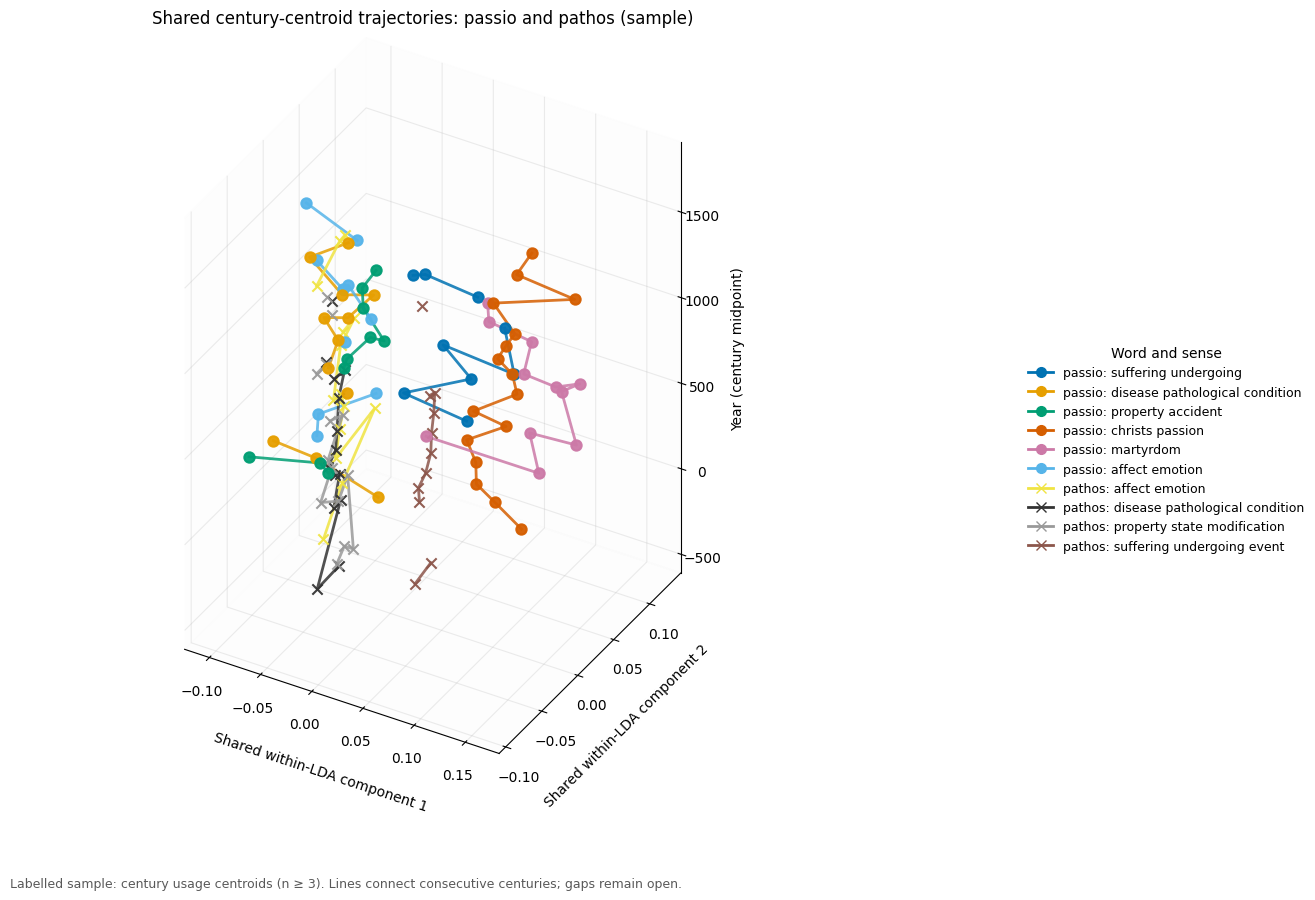

In [34]:
# Century centroids from the labelled sample in the existing shared space.
lineage_variant_name = "sample"
v = VARIANTS[lineage_variant_name]
LINEAGE_CENTURIES = {}
for t in WITHIN_SHARED_TERMS:
    df = v[t]["df"]
    Z = np.asarray(WITHIN_SHARED_COORDS[lineage_variant_name][t])
    y = np.asarray(v[t]["y"])
    if len(df) != len(Z) or len(df) != len(y):
        raise ValueError("Centuries, coordinates and labels must be aligned.")
    centuries = pd.to_numeric(df["century"], errors="coerce").to_numpy(dtype=float)
    valid = np.isfinite(centuries) & np.isfinite(Z).all(axis=1)
    d = pd.DataFrame({"sense": y[valid], "year": centuries[valid],
                      "x": Z[valid, 0], "y": Z[valid, 1]})
    if "grela_id" in df:
        d["work"] = df.loc[valid, "grela_id"].to_numpy()
    agg = {"x": ("x", "mean"), "y": ("y", "mean"), "n": ("x", "size")}
    if "work" in d:
        agg["n_works"] = ("work", "nunique")
    points = d.groupby(["sense", "year"], as_index=False).agg(**agg)
    points["valid"] = points["n"] >= WITHIN_SHARED_MIN_CENTURY
    LINEAGE_CENTURIES[t] = points.sort_values(["sense", "year"])
    print(f"{t} ({lineage_variant_name}): {len(points)} populated sense-century bins; "
          f"{int(points['valid'].sum())} have at least {WITHIN_SHARED_MIN_CENTURY} usages")
    columns = [c for c in ["sense", "year", "n", "n_works", "valid"] if c in points]
    display(LINEAGE_CENTURIES[t][columns])


fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection="3d")
handles = []
for t in WITHIN_SHARED_TERMS:
    for s in sorted(SENSE_NAMES[t]):
        color, marker = SENSE_PALETTE[t][s], WITHIN_SHARED_MARKERS[t]
        points = LINEAGE_CENTURIES[t]
        g = points[(points["sense"] == s) & points["valid"]].sort_values("year")
        if g.empty:
            continue
        # Consecutive century midpoints are 100 years apart, including BCE -> CE.
        runs = np.split(np.arange(len(g)), np.flatnonzero(np.diff(g["year"]) != 100) + 1)
        for run in runs:
            r = g.iloc[run]
            if len(r) > 1:
                ax.plot(r["x"], r["y"], r["year"], color=color, lw=2, alpha=.85)
        ax.scatter(g["x"], g["y"], g["year"], color=color, marker=marker,
                   s=55, alpha=.95, depthshade=False, linewidths=1.5)
        handles.append(Line2D([0], [0], color=color, marker=marker, linewidth=2,
                             markersize=7, label=f"{t}: {SENSE_NAMES[t][s]}"))
ax.set_xlabel("Shared within-LDA component 1", labelpad=10)
ax.set_ylabel("Shared within-LDA component 2", labelpad=10)
ax.set_zlabel("Year (century midpoint)", labelpad=10)
ax.view_init(elev=WITHIN_SHARED_ELEV, azim=WITHIN_SHARED_AZIM)
ax.set_proj_type("ortho")
ax.set_box_aspect((1, 1, 1.45))
ax.set_title("Shared century-centroid trajectories: passio and pathos (sample)", pad=18)
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis.set_pane_color((.98, .98, .98, .25))
    axis._axinfo["grid"]["color"] = (.7, .7, .7, .25)
fig.legend(handles=handles, loc="center right", frameon=False, fontsize=9, title="Word and sense")
note = (f"Labelled sample: century usage centroids (n ≥ {WITHIN_SHARED_MIN_CENTURY}). "
        "Lines connect consecutive centuries; gaps remain open.")
fig.text(.07, .008, note, fontsize=9, color=".35")
fig.tight_layout(rect=(0, .13, .73, 1))
output = FIGDIR / f"figure2-within-lda-shared-trajectories-{lineage_variant_name}"
fig.savefig(output.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(output.with_suffix(".pdf"), bbox_inches="tight")
plt.show()


## Notes

- **Variants**: `sample` (scatter/2-D, ERC figure and shared century trajectories) and
  `full` (other lineage and composition figures). Regenerate `full` with `6_embedding-classification-applied.ipynb`.
- **LDA is supervised** (uses labels to choose axes). §4 tells you how much the label-free
  view (§5) already carries.
- **Judge a projection by a classifier/kNN, not by silhouette alone** — silhouette rewards
  compact blobs and under-rates elongated, separable clusters (e.g. pathos).
- **Colour** is fixed per `(lexeme, sense)` in `SENSE_PALETTE` (curated Okabe–Ito palette),
  so the same sense keeps the same colour across every figure.
- Figures are written to `figures/` (kept out of the notebook to avoid a huge `.ipynb`).